# Gene functions and pathway interpretation

Companion to [gene_interactions_interpretation.ipynb](gene_interactions_interpretation.ipynb).
Ask whether the selected genes reflect broader interferon, inflammatory and neutrophil programs, and whether those programs remain associated with TB after accounting for estimated RNA contributions from different cell groups.

## Summary
**The interferon-gamma expression program has the most consistent support beyond the selected genes.** Its TB difference after accounting for study differences and estimated RNA contributions is +0.95, +0.76 and +1.02 training SD in training, test and validation, respectively; all three pass BH FDR < 0.05 across the 30 pathway-score comparisons. Validation also supports interferon-alpha. Validation's inflammatory, neutrophil and TNF pathway-score intervals include zero, despite positive gene-set enrichment. Therefore those broader programs are less consistently supported.

The analysis ranks **11,264 gene symbols**, tests 50 adequately covered pathways and repeats while also accounting for estimated RNA contributions and exclusion of the XGBoost six. These analyses are **exploratory**: both held-out datasets have already been inspected. Pathway enrichment and adjusted associations do not establish pathway activation within a particular cell type.

## Gene-focused extension
Sections 7–11 connect **gene function → curated membership → observed expression → broader programs → gene combinations**. The XGBoost six are the focus; the paper panel supplies a fair biological comparison. Literature motivated three additional programs: IL2–STAT5, megakaryocyte/platelet production, and a signed SPI1 target-expression score. All new program scores exclude the **union of both panels (11 genes)** to avoid direct self-inclusion. The original five-pathway analyses above retain their definitions and BH30 family.

The added analyses are exploratory follow-ups in already inspected datasets. They do not establish a single causal pathway, cell-intrinsic activity, or biological epistasis.


**What the extension adds:** GBP5 tracks broader interferon expression in all three datasets. MNDA and SPI1 track neutrophil-related and SPI1-target programs, with residual MNDA–SPI1 correlations of 0.70, 0.66 and 0.72 after accounting for TB status, study differences and estimated RNA contributions. LYZ is less consistent in validation. The proposed AHNAK–IL2/STAT5 and JMJD1C–megakaryocyte links are not consistently supported by these samples. These distinctions support a layered biological interpretation, while leaving uncertain roles explicit.


Run [gene_interactions.ipynb](gene_interactions.ipynb) first to produce the shared, checked expression cache. Use the same `cfrna-tb` environment plus `gseapy==1.1.13`.

## 1. Context and methods

- Reuse the main notebook's **training-reference DESeq2 VST**. Retain genes with at least 10 reads in at least 13 training participants (10%); this filtering does not use TB labels. Do not restrict the analysis to the 142 TB-selected candidates.
- Analyze training, test and validation separately. First compare TB-positive and TB-negative participants while accounting for which study recruited them. Repeat while also accounting for the estimated RNA contributions from different cell groups, defined below. Rank genes by the TB coefficient divided by its HC3 robust standard error. Positive statistics indicate higher expression in TB-positive participants. Validation contains one study, so no study indicator is fitted there.
- Use the **50 Hallmark gene sets plus Reactome neutrophil degranulation**, from the pinned MSigDB 2026.1 human release. The five biological themes are specified below before examining these pathway results. Offer all 51 sets to [GSEApy prerank](https://gseapy.readthedocs.io/en/latest/run.html), 1,000 gene-set permutations, seed 87, and 15–500 expressed genes per set. GSEA FDR is calculated separately over the eligible pathways in each analysis; it is not a correction across all sensitivity analyses.
- Repeat enrichment after removing **GBP5, AHNAK, JMJD1C, MNDA, LYZ and SPI1** from the entire ranked list. This asks whether support extends beyond the XGBoost panel; it does not make the previously inspected samples independent.
- As a complementary check, fit participant-level mean expression scores for the five specified pathways, excluding the same six genes. These models retain within-pathway gene correlations and report HC3 intervals plus Benjamini–Hochberg FDR across 30 pathway-score comparisons.

### What the two figure labels mean

- **Study:** the comparison includes which study recruited each participant.
- **Study + RNA mix:** the comparison also includes estimates of where each participant's plasma RNA came from. The groups are **myeloid** (including monocytes, macrophages and neutrophils), **lymphoid** (including T, B and natural killer cells), **erythroid/platelet** (red-blood-cell lineage and platelets), and **other** reference cell types.

For example, an immune-gene signal can be higher when more of a sample's RNA comes from immune cells. The second comparison asks whether a TB difference remains after accounting for those estimated RNA shares. These estimates describe **RNA shares, not numbers of cells**. Validation contains only one study, so neither model fits a study term there.

### Key assumptions
The RNA-share estimates use the existing plasma fractions in `Files_For_Manuscript/discovery_cell_types.tsv`, covering all 251 participants and grouped as myeloid, lymphoid, erythroid/platelet and other. Use three `log(group / other)` ratios; all groups are positive. These are **RNA contributions, not cell counts**. They derive from the same cfRNA data, and their uncertainty is not propagated. Accounting for these estimates is a sensitivity analysis, not a causal separation of cellular activation and source mixture. The [gene-excluded deconvolution companion](gene_interactions_deconvolution.ipynb) is an **optional robustness check**; these completed pathway results do not depend on that rerun. `cto_wb.txt` contains distinct whole-blood estimates for an optional paired assay comparison and is not used here.

Gene-set permutation GSEA does not preserve expression correlations between genes. Its FDR is therefore exploratory; the participant-level pathway-score check provides a complementary summary, not a formal replication. Mean expression is also a proxy, not a biochemical activity measurement.

Sources: [MSigDB 2026.1 files](https://data.broadinstitute.org/gsea-msigdb/msigdb/release/2026.1.Hs/), [Hallmark collection](https://www.gsea-msigdb.org/gsea/msigdb/human/collections.jsp#H), [Reactome neutrophil degranulation](https://www.reactome.org/content/detail/R-HSA-6798695), [GSEA method](https://www.gsea-msigdb.org/gsea/doc/subramanian_tamayo_gsea_pnas.pdf).

### Figure presentation

Use short plot labels, one shared adjustment key, and full definitions in the adjacent figure legends. Presentation examples: [Nature Medicine, Figure 2](https://www.nature.com/articles/s41591-025-03570-5/figures/2) and a [published gene-correlation heatmap, Figure 7](https://pmc.ncbi.nlm.nih.gov/articles/PMC11645277/#Fig7). See also [Nature's figure guidance](https://research-figure-guide.nature.com/figures/preparing-figures-our-specifications/).


In [1]:
import hashlib
import json
import os
from importlib.metadata import version
from pathlib import Path

# Keep numerical libraries modest on the shared HPC, including interactive reruns.
for variable in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"]:
    os.environ[variable] = "1"

import gseapy as gp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import Markdown, display
from scipy.stats import t
from statsmodels.stats.multitest import multipletests
from threadpoolctl import threadpool_limits

numeric_thread_limit = threadpool_limits(limits=1)
GSEA_WORKERS = 2

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Files_For_Manuscript").is_dir())
DATA = ROOT / "Files_For_Manuscript"
OUTPUT = ROOT / "Figure_Output/Gene_Interactions/focused"
RESOURCES = DATA / "gene_interactions_reference"
SPLITS = {"train": "Training", "test": "Test", "val": "Validation"}
SEED = 87
sns.set_theme(style="ticks", context="paper")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.labelsize": 10, "axes.titlesize": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "savefig.dpi": 300, "pdf.fonttype": 42})

def save_figure(figure, output_dir, name):
    for extension in ["png", "pdf"]:
        figure.savefig(output_dir / f"{name}.{extension}", bbox_inches="tight")

SELECTED = ["GBP5", "AHNAK", "JMJD1C", "MNDA", "LYZ", "SPI1"]
FOCUS = {
    "HALLMARK_INTERFERON_ALPHA_RESPONSE": "Interferon alpha",
    "HALLMARK_INTERFERON_GAMMA_RESPONSE": "Interferon gamma",
    "HALLMARK_TNFA_SIGNALING_VIA_NFKB": "TNF / NF-kB",
    "HALLMARK_INFLAMMATORY_RESPONSE": "Inflammatory response",
    "REACTOME_NEUTROPHIL_DEGRANULATION": "Neutrophil degranulation",
}
ADJUSTMENTS = ["Cohort", "Cohort + composition"]
PANELS = ["All expressed genes", "Exclude XGBoost six"]
PERMUTATIONS = 1000

# Compact labels are defined in each adjacent figure legend; saved keys stay stable.
ADJUSTMENT_LABELS = {ADJUSTMENTS[0]: "Study", ADJUSTMENTS[1]: "Study + RNA mix"}
ADJUSTMENT_TITLES = ADJUSTMENT_LABELS
ADJUSTMENT_MARKERS = {ADJUSTMENTS[0]: "o", ADJUSTMENTS[1]: "s"}
PANEL_TITLES = {PANELS[0]: "All genes", PANELS[1]: "Six genes excluded"}
RNA_CONTRIBUTION_NOTE = "RNA mix: estimated plasma RNA shares from different cell groups."

def add_figure_caption(figure, statistical_note):
    """Keep only a short key in the plot; full definitions are in the figure legend."""
    figure.text(0.015, 0.04 / figure.get_figheight(),
                statistical_note + "\n" + RNA_CONTRIBUTION_NOTE,
                ha="left", va="bottom", fontsize=9, linespacing=1.4)

def finish_association_figure(figure, axes, title, xlabel):
    """Use physical margins so short labels do not leave a large empty canvas."""
    height = figure.get_figheight()
    figure.suptitle(title, y=0.995, fontsize=12)
    figure.legend(*axes[0].get_legend_handles_labels(), loc="upper center",
                  bbox_to_anchor=(0.57, 1 - 0.24 / height), ncol=2,
                  title="Adjustment", frameon=False, fontsize=10, title_fontsize=9)
    figure.supxlabel(xlabel, y=0.49 / height, fontsize=10)
    add_figure_caption(figure, "Points and bars: estimates and 95% CI.  * FDR < 0.05.")
    figure.subplots_adjust(left=0.205, right=0.985, bottom=0.90 / height,
                           top=1 - 1.05 / height, wspace=0.12)


## 2. Load expression, metadata and pathway membership

Keep gene symbols with unambiguous annotations; if multiple eligible Ensembl genes share a symbol, average their VST expression without looking at TB. Retain the complete mapping and pathway-coverage tables for inspection. The archived GMT files are read locally, so rerunning does not silently change pathway definitions. The pancreas beta-cell set has only 12 eligible genes and is excluded by the 15-gene minimum; the other **50 sets** are tested. None of the six selected genes belongs to the four specified Hallmark sets; the neutrophil set contains MNDA and LYZ (404 expressed genes, 402 after exclusion). Removing genes from the ranked background can still change GSEA NES even when a pathway loses no members.

In [2]:
metadata = pd.concat([
    pd.read_csv(DATA / f"metadata.{split}.tsv", sep="\t", index_col="sample_id").assign(split=split)
    for split in SPLITS
])
metadata["tb_positive"] = metadata.tb.eq("positive").astype(int)
assert metadata.index.is_unique

# This checked expression cache is produced by gene_interactions.ipynb.
manifest = json.loads((RESOURCES / "expression_training_vst.json").read_text())
for relative_path, expected_hash in {**manifest["inputs"], **manifest["artifacts"]}.items():
    assert hashlib.sha256((ROOT / relative_path).read_bytes()).hexdigest() == expected_hash, relative_path
with np.load(RESOURCES / "expression_training_vst.npz", allow_pickle=False) as cached:
    expression = pd.DataFrame(cached["values"], index=cached["samples"], columns=cached["genes"])
eligible_genes = pd.read_csv(RESOURCES / "eligible_genes.csv").gene_id
expression = expression.loc[metadata.index, eligible_genes]
# Only annotation is read from the pooled DE file, never its association statistics.
names = pd.read_csv(DATA / "deseq_results.tsv", sep="\t", usecols=["gene_id", "gene_name"]).set_index("gene_id").gene_name
names = names.reindex(expression.columns)
valid_names = names.notna() & names.ne("")
gene_mapping = pd.DataFrame({"gene_id": expression.columns, "gene_name": names.to_numpy(),
                             "has_symbol": valid_names.to_numpy()})
gene_mapping.to_csv(OUTPUT / "pathway_eligible_gene_mapping.csv", index=False)
expression = expression.loc[:, valid_names]
expression.columns = names.loc[valid_names].to_numpy()
expression = expression.T.groupby(level=0, sort=True).mean().T
assert expression.index.equals(metadata.index) and expression.columns.is_unique
assert set(SELECTED).issubset(expression.columns) and np.isfinite(expression).all().all()

original_inputs = pd.read_csv(OUTPUT / "myeloid_analysis_inputs.csv", index_col="sample_id")
composition_columns = ["rna_myeloid_vs_other", "rna_lymphoid_vs_other", "rna_erythroid_platelet_vs_other"]
assert original_inputs.loc[metadata.index, ["cohort", "tb", "split"]].equals(metadata[["cohort", "tb", "split"]])
metadata = metadata.join(original_inputs[composition_columns])
assert not metadata[composition_columns].isna().any().any()

def read_gmt(path):
    with path.open() as handle:
        fields = [line.rstrip().split("\t") for line in handle]
    return {row[0]: list(dict.fromkeys(row[2:])) for row in fields}

hallmark_file = RESOURCES / "pathways_hallmark_2026.1.gmt"
reactome_file = RESOURCES / "pathways_reactome_2026.1.gmt"
gene_sets = read_gmt(hallmark_file)
gene_sets["REACTOME_NEUTROPHIL_DEGRANULATION"] = read_gmt(reactome_file)["REACTOME_NEUTROPHIL_DEGRANULATION"]
assert len(gene_sets) == 51
coverage = pd.DataFrame([
    {"pathway": term, "database_genes": len(genes), "expressed_genes": len(set(genes) & set(expression.columns)),
     "expressed_after_exclusion": len(set(genes) & (set(expression.columns) - set(SELECTED))),
     "selected_overlap": ";".join(g for g in SELECTED if g in genes)}
    for term, genes in gene_sets.items()
]).set_index("pathway")
coverage["eligible_for_gsea"] = coverage.expressed_genes.between(15, 500) & coverage.expressed_after_exclusion.between(15, 500)
coverage.to_csv(OUTPUT / "pathway_gene_coverage.csv")
print(f"{coverage.eligible_for_gsea.sum()} of {len(coverage)} pathways meet the gene-set size rule.")
print(f"{len(metadata)} participants; {len(gene_mapping):,} eligible Ensembl genes; {expression.shape[1]:,} mapped symbols.")
display(pd.crosstab([metadata.split, metadata.cohort], metadata.tb).reindex(SPLITS, level=0))
display(coverage.loc[list(FOCUS)].rename(index=FOCUS))

50 of 51 pathways meet the gene-set size rule.
251 participants; 11,279 eligible Ensembl genes; 11,264 mapped symbols.


tb              negative  positive
split cohort                      
train GHL             24        39
      R2D2            33        34
test  GHL             12        18
      R2D2            15        16
val   TBSQUARE        25        35

,database_genes,expressed_genes,expressed_after_exclusion,selected_overlap,eligible_for_gsea
pathway,,,,,
Interferon alpha,97,91,91,,True
Interferon gamma,200,185,185,,True
TNF / NF-kB,200,157,157,,True
Inflammatory response,200,132,132,,True
Neutrophil degranulation,478,404,402,MNDA;LYZ,True


## 3. Rank the TB association across expressed genes

Use the same participant set for both adjustments within each dataset. Save the full gene-level coefficients, robust standard errors and ranks. Here the association model explains expression; it is not another TB prediction model.

In [3]:
def make_design(frame, adjustment):
    design = frame[["tb_positive"]].astype(float).copy()
    design = design.join(pd.get_dummies(frame.cohort, prefix="cohort", drop_first=True, dtype=float))
    if adjustment == "Cohort + composition":
        design = design.join(frame[composition_columns])
    design = sm.add_constant(design, has_constant="add")
    assert np.linalg.matrix_rank(design) == design.shape[1]
    return design

rankings, gene_results, design_rows = {}, [], []
for split, split_label in SPLITS.items():
    frame = metadata.loc[metadata.split.eq(split)]
    for adjustment in ADJUSTMENTS:
        design = make_design(frame, adjustment)
        rows = []
        for gene, gene_expression in expression.items():
            fit = sm.OLS(gene_expression.loc[frame.index], design, missing="raise").fit(cov_type="HC3", use_t=True)
            rows.append({"gene": gene, "tb_difference": fit.params.tb_positive,
                         "robust_se": fit.bse.tb_positive, "rank_statistic": fit.tvalues.tb_positive,
                         "nominal_p": fit.pvalues.tb_positive})
        result = pd.DataFrame(rows).assign(split=split, adjustment=adjustment)
        assert np.isfinite(result[["tb_difference", "robust_se", "rank_statistic", "nominal_p"]]).all().all()
        rankings[split, adjustment] = result.set_index("gene").rank_statistic.sort_values(ascending=False, kind="stable")
        gene_results.append(result)
        print(f"Ranked {len(result):,} genes: {split_label} | {adjustment}")
        design_rows.append({"split": split, "adjustment": adjustment, "participants": len(frame),
                            "parameters": design.shape[1], "condition_number": np.linalg.cond(design),
                            "rank_ties": rankings[split, adjustment].duplicated().sum()})
gene_results = pd.concat(gene_results, ignore_index=True)
gene_results.to_csv(OUTPUT / "pathway_gene_tb_associations.csv.gz", index=False)
design_audit = pd.DataFrame(design_rows)
design_audit.to_csv(OUTPUT / "pathway_association_designs.csv", index=False)
display(design_audit)

Ranked 11,264 genes: Training | Cohort


Ranked 11,264 genes: Training | Cohort + composition


Ranked 11,264 genes: Test | Cohort


Ranked 11,264 genes: Test | Cohort + composition


Ranked 11,264 genes: Validation | Cohort


Ranked 11,264 genes: Validation | Cohort + composition


,split,adjustment,participants,parameters,condition_number,rank_ties
0,train,Cohort,130,3,3.558153,0
1,train,Cohort + composition,130,6,9.763603,0
2,test,Cohort,61,3,3.480262,0
3,test,Cohort + composition,61,6,8.042206,0
4,val,Cohort,60,2,2.862205,0
5,val,Cohort + composition,60,5,6.339435,0


## 4. Test pathway enrichment and exclude the selected genes

Positive normalized enrichment scores (NES) indicate concentration toward higher TB-associated expression; negative values indicate concentration toward lower expression. GSEA FDR is the software's permutation-based estimate over the 50 eligible pathways for each analysis. Empirical values of zero mean below the permutation resolution, not zero probability.

In [4]:
enrichment_rows = []
for (split, adjustment), ranking in rankings.items():
    for panel in PANELS:
        selected_ranking = ranking if panel == PANELS[0] else ranking.drop(SELECTED)
        result = gp.prerank(rnk=selected_ranking, gene_sets=gene_sets, outdir=None,
                            min_size=15, max_size=500, permutation_num=PERMUTATIONS,
                            seed=SEED, threads=GSEA_WORKERS, no_plot=True, verbose=False)
        table = result.res2d.rename(columns={"Term": "pathway", "ES": "enrichment_score", "NES": "nes",
            "NOM p-val": "nominal_p", "FDR q-val": "gsea_fdr", "Lead_genes": "leading_edge_genes"})
        table = table[["pathway", "enrichment_score", "nes", "nominal_p", "gsea_fdr", "leading_edge_genes"]].copy()
        table[["enrichment_score", "nes", "nominal_p", "gsea_fdr"]] = table[["enrichment_score", "nes", "nominal_p", "gsea_fdr"]].astype(float)
        table["ranked_genes"] = len(selected_ranking)
        table["pathway_genes_tested"] = table.pathway.map(lambda term, ranked=set(selected_ranking.index): len(set(gene_sets[term]) & ranked))
        enrichment_rows.append(table.assign(split=split, adjustment=adjustment, panel=panel))
        print(f"{SPLITS[split]} | {adjustment} | {panel}: {len(table)} pathways")
enrichment = pd.concat(enrichment_rows, ignore_index=True)
assert not enrichment.duplicated(["split", "adjustment", "panel", "pathway"]).any()
assert np.isfinite(enrichment[["nes", "nominal_p", "gsea_fdr"]]).all().all()
assert enrichment.loc[enrichment.panel.eq(PANELS[1]), "leading_edge_genes"].str.split(";").map(lambda genes: not set(genes) & set(SELECTED)).all()
enrichment.to_csv(OUTPUT / "pathway_enrichment.csv", index=False)

Training | Cohort | All expressed genes: 50 pathways


Training | Cohort | Exclude XGBoost six: 50 pathways


Training | Cohort + composition | All expressed genes: 50 pathways


Training | Cohort + composition | Exclude XGBoost six: 50 pathways


Test | Cohort | All expressed genes: 50 pathways


...

Test | Cohort + composition | Exclude XGBoost six: 50 pathways


Validation | Cohort | All expressed genes: 50 pathways


Validation | Cohort | Exclude XGBoost six: 50 pathways


Validation | Cohort + composition | All expressed genes: 50 pathways


Validation | Cohort + composition | Exclude XGBoost six: 50 pathways


### The five specified biological themes

Each heatmap uses the same color scale. An asterisk marks GSEA FDR < 0.05 within the 50 eligible pathways. Compare the left and right columns to assess how much the six selected genes contribute to the broader pattern, and the top and bottom rows to assess sensitivity to estimated RNA contributions from different cell groups.

**Figure legend — Pathway enrichment.** Columns compare all expressed genes with the six XGBoost genes excluded; rows compare the two adjustments. Numbers and colors show normalized enrichment scores (NES); positive values indicate pathway genes concentrated toward higher expression in TB. Asterisks mark a gene-set-enrichment false discovery rate (FDR) below 0.05, calculated separately within each analysis of 50 pathways. No confidence intervals are shown.

**Adjustment key:** **Study** accounts for which study recruited each participant; **Study + RNA mix** additionally accounts for estimated plasma RNA shares from myeloid cells (including monocytes, macrophages and neutrophils), lymphoid cells (including T, B and natural killer cells), erythroid cells/platelets, and other reference cell types. These are estimated RNA shares, not cell counts. Validation contains one study, so no study indicator is fitted there.

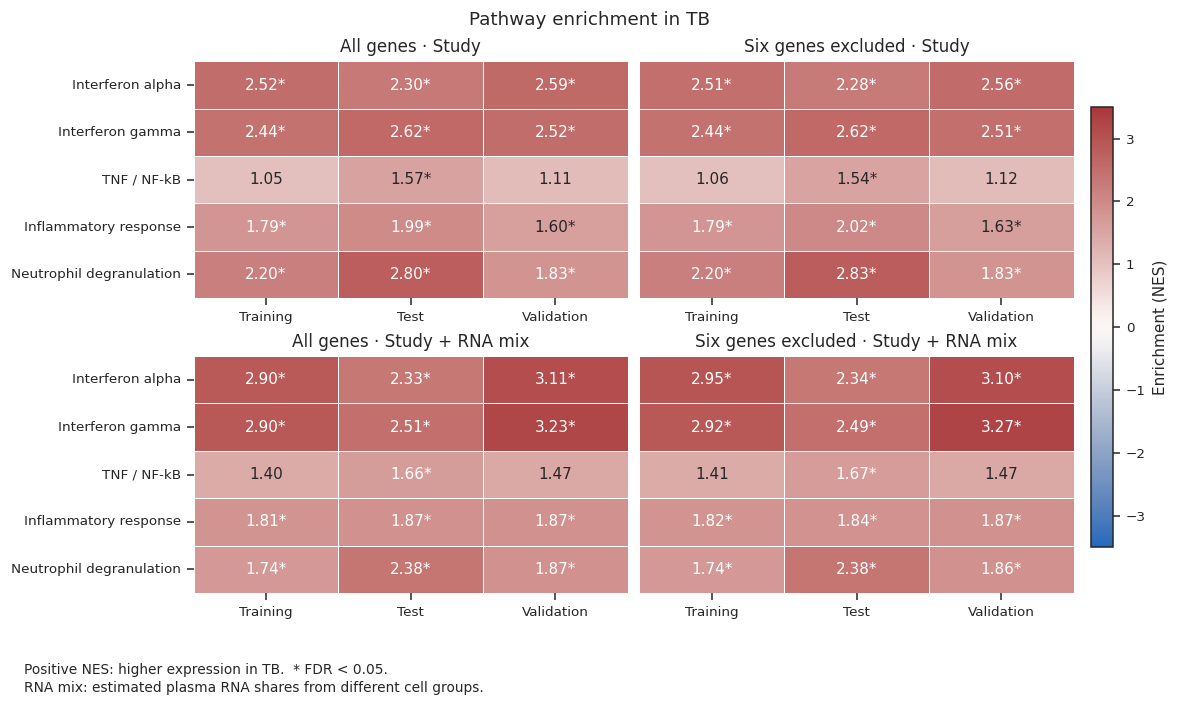

In [5]:
focus_results = enrichment.loc[enrichment.pathway.isin(FOCUS)].copy()
figure, axes = plt.subplots(2, 2, figsize=(10.6, 6.3), layout="constrained")
limit = max(2, np.ceil(focus_results.nes.abs().max() * 2) / 2)
for row, adjustment in enumerate(ADJUSTMENTS):
    for column, panel in enumerate(PANELS):
        data = focus_results.loc[focus_results.adjustment.eq(adjustment) & focus_results.panel.eq(panel)]
        values = data.pivot(index="pathway", columns="split", values="nes").reindex(index=FOCUS, columns=SPLITS)
        fdr = data.pivot(index="pathway", columns="split", values="gsea_fdr").reindex_like(values)
        labels = values.map(lambda value: f"{value:.2f}") + fdr.map(lambda value: "*" if value < 0.05 else "")
        sns.heatmap(values, ax=axes[row, column], annot=labels, fmt="", cmap="vlag", center=0,
                    vmin=-limit, vmax=limit, cbar=False, linewidths=0.5,
                    xticklabels=list(SPLITS.values()), yticklabels=list(FOCUS.values()) if column == 0 else False)
        axes[row, column].set(title=f"{PANEL_TITLES[panel]} · {ADJUSTMENT_TITLES[adjustment]}", xlabel="", ylabel="")
        axes[row, column].tick_params(axis="both", rotation=0)
figure.colorbar(axes[0, 0].collections[0], ax=axes, fraction=0.025, pad=0.02, label="Enrichment (NES)")
figure.suptitle("Pathway enrichment in TB", fontsize=12)
figure.set_layout_engine("constrained", rect=(0, 0.11, 1, 0.89))
add_figure_caption(figure, "Positive NES: higher expression in TB.  * FDR < 0.05.")
save_figure(figure, OUTPUT, "pathway_focused_enrichment")
plt.show()
focus_results.to_csv(OUTPUT / "pathway_focused_enrichment.csv", index=False)

### Broader Hallmark screen

Display eight positive and eight negative Hallmark pathways with the most extreme training NES after accounting for study differences. This display rule uses training only; all 50 eligible pathways remain in the exported results. It is a descriptive overview, not selection of a new predictive signature.

**Figure legend — Hallmark pathway enrichment.** The 16 displayed pathways have the eight highest and eight lowest training enrichment scores under study adjustment. All expressed genes are included. Numbers and colors show normalized enrichment scores (NES); positive values indicate pathway genes concentrated toward higher expression in TB. Asterisks mark a gene-set-enrichment false discovery rate (FDR) below 0.05, calculated separately within each analysis of 50 pathways. No confidence intervals are shown.

**Adjustment key:** **Study** accounts for which study recruited each participant; **Study + RNA mix** additionally accounts for estimated plasma RNA shares from myeloid cells (including monocytes, macrophages and neutrophils), lymphoid cells (including T, B and natural killer cells), erythroid cells/platelets, and other reference cell types. These are estimated RNA shares, not cell counts. Validation contains one study, so no study indicator is fitted there.

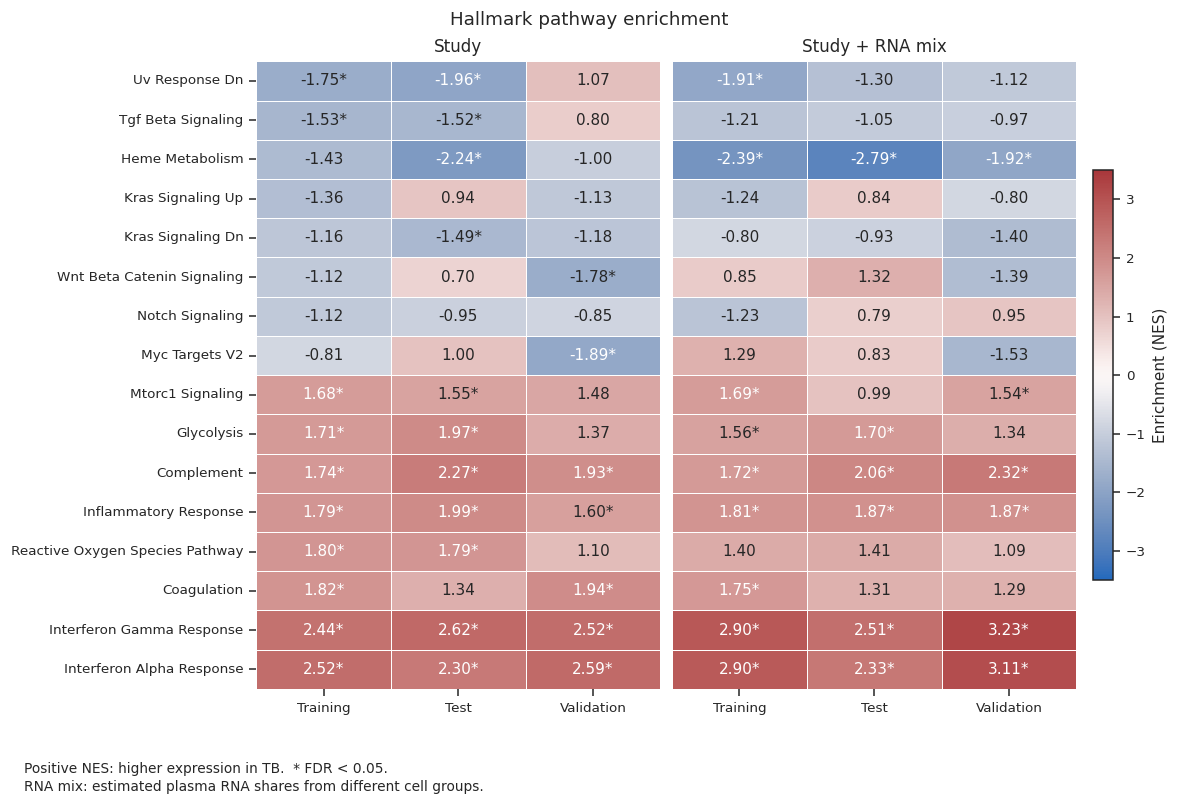

In [6]:
primary = enrichment.loc[enrichment.panel.eq(PANELS[0]) & enrichment.pathway.str.startswith("HALLMARK_")]
training = primary.loc[primary.split.eq("train") & primary.adjustment.eq(ADJUSTMENTS[0])].sort_values("nes")
shown = list(training.head(8).pathway) + list(training.tail(8).pathway)
figure, axes = plt.subplots(1, 2, figsize=(10.6, 7.2), layout="constrained")
limit = max(2, np.ceil(primary.nes.abs().max() * 2) / 2)
for column, (axis, adjustment) in enumerate(zip(axes, ADJUSTMENTS)):
    data = primary.loc[primary.adjustment.eq(adjustment)]
    values = data.pivot(index="pathway", columns="split", values="nes").reindex(index=shown, columns=SPLITS)
    fdr = data.pivot(index="pathway", columns="split", values="gsea_fdr").reindex_like(values)
    labels = values.map(lambda value: f"{value:.2f}") + fdr.map(lambda value: "*" if value < 0.05 else "")
    sns.heatmap(values, ax=axis, annot=labels, fmt="", center=0, cmap="vlag", vmin=-limit, vmax=limit,
                cbar=False, linewidths=0.5, xticklabels=list(SPLITS.values()),
                yticklabels=[term.removeprefix("HALLMARK_").replace("_", " ").title() for term in shown] if column == 0 else False)
    axis.set(title=ADJUSTMENT_TITLES[adjustment], xlabel="", ylabel="")
    axis.tick_params(axis="both", rotation=0)
figure.colorbar(axes[0].collections[0], ax=axes, fraction=0.025, pad=0.02, label="Enrichment (NES)")
figure.suptitle("Hallmark pathway enrichment", fontsize=12)
figure.set_layout_engine("constrained", rect=(0, 0.10, 1, 0.90))
add_figure_caption(figure, "Positive NES: higher expression in TB.  * FDR < 0.05.")
save_figure(figure, OUTPUT, "pathway_hallmark_overview")
plt.show()

## 5. Check participant-level pathway expression

For each specified pathway, exclude the six selected genes, standardize each remaining gene using training mean and SD, and average the gene z scores. Finally scale the pathway score by its own training SD. A coefficient of 1 means a TB-associated difference of one training SD in this pathway expression summary.

Fit the same two adjustment models to these participant-level scores. The HC3 intervals use residual degrees of freedom. BH FDR covers all 5 pathways × 3 datasets × 2 adjustments (30 tests). These scores retain the observed correlations among genes; they do not use a gene-set permutation null.

**Figure legend — Pathway expression without the six genes.** Points show the estimated TB-positive minus TB-negative difference; bars show 95% confidence intervals (CI), using HC3 robust standard errors and Student-t cutoffs. SD means the training standard deviation of the **pathway score**, after averaging standardized expression across its remaining genes. Positive values indicate higher expression in TB. Both models exclude all six selected genes from the scores. Asterisks indicate false discovery rate (FDR) below 0.05 after Benjamini–Hochberg correction across 30 comparisons.

**Adjustment key:** **Study** accounts for which study recruited each participant; **Study + RNA mix** additionally accounts for estimated plasma RNA shares from myeloid cells (including monocytes, macrophages and neutrophils), lymphoid cells (including T, B and natural killer cells), erythroid cells/platelets, and other reference cell types. These are estimated RNA shares, not cell counts. Validation contains one study, so no study indicator is fitted there.

In [7]:
train_expression = expression.loc[metadata.split.eq("train")]
standardized = (expression - train_expression.mean()) / train_expression.std(ddof=1)
assert np.isfinite(standardized).all().all()
pathway_scores = pd.DataFrame(index=metadata.index)
score_members = {}
for term in FOCUS:
    genes = sorted((set(gene_sets[term]) & set(expression.columns)) - set(SELECTED))
    score_members[term] = genes
    score = standardized[genes].mean(axis=1)
    pathway_scores[term] = score / score.loc[metadata.split.eq("train")].std(ddof=1)
pathway_scores.to_csv(OUTPUT / "pathway_expression_scores.csv")
(OUTPUT / "pathway_score_members.json").write_text(json.dumps(score_members, indent=2))
score_rows = []
for split in SPLITS:
    frame = metadata.loc[metadata.split.eq(split)]
    for adjustment in ADJUSTMENTS:
        design = make_design(frame, adjustment)
        for term in FOCUS:
            fit = sm.OLS(pathway_scores.loc[frame.index, term], design, missing="raise").fit(cov_type="HC3", use_t=True)
            lower, upper = fit.conf_int().loc["tb_positive"]
            score_rows.append({"pathway": term, "split": split, "adjustment": adjustment, "n": len(frame),
                "genes": len(score_members[term]), "tb_difference": fit.params.tb_positive,
                "ci_lower": lower, "ci_upper": upper, "nominal_p": fit.pvalues.tb_positive})
score_results = pd.DataFrame(score_rows)
score_results["bh_fdr_30"] = multipletests(score_results.nominal_p, method="fdr_bh")[1]
score_results.to_csv(OUTPUT / "pathway_score_tb_associations.csv", index=False)
score_overlap = pd.DataFrame({a: {b: len(set(score_members[a]) & set(score_members[b])) for b in FOCUS} for a in FOCUS})
score_overlap.to_csv(OUTPUT / "pathway_gene_overlap_counts.csv")

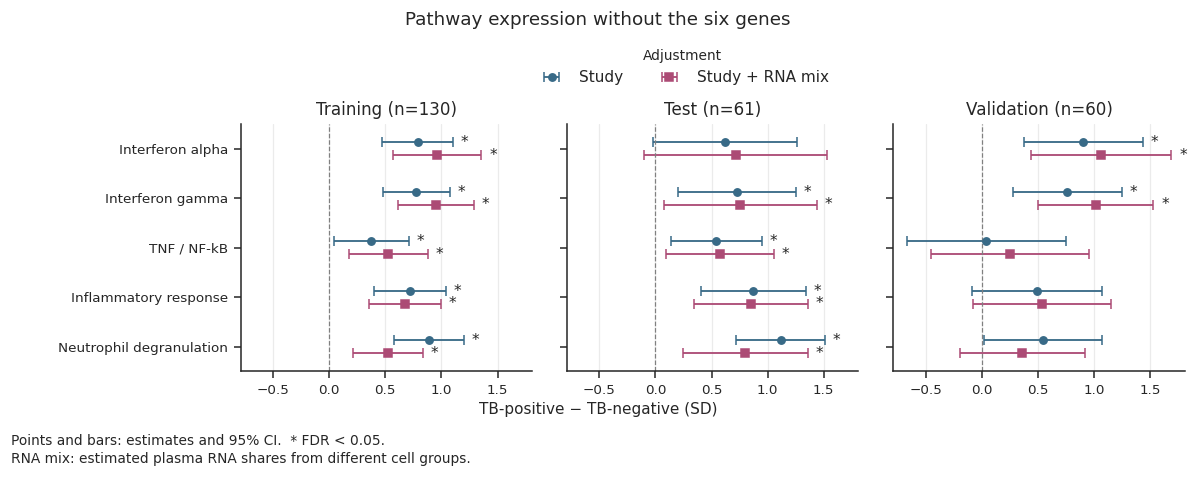

pathway,split,genes,tb_difference,ci_lower,ci_upper,bh_fdr_30
Interferon alpha,Training,91,0.962,0.568,1.357,0.000
Interferon gamma,Training,185,0.951,0.610,1.291,0.000
TNF / NF-kB,Training,157,0.528,0.178,0.877,0.006
Inflammatory response,Training,132,0.676,0.353,0.998,0.000
Neutrophil degranulation,Training,402,0.524,0.210,0.837,0.003
Interferon alpha,Test,91,0.715,-0.099,1.529,0.098
Interferon gamma,Test,185,0.757,0.077,1.437,0.041
TNF / NF-kB,Test,157,0.576,0.096,1.057,0.029
Inflammatory response,Test,132,0.852,0.341,1.362,0.003
Neutrophil degranulation,Test,402,0.800,0.246,1.355,0.010


In [8]:
figure, axes = plt.subplots(1, 3, figsize=(11, 4.2), sharex=True, sharey=True)
colors = {ADJUSTMENTS[0]: "#386A87", ADJUSTMENTS[1]: "#AC4B75"}
for axis, split in zip(axes, SPLITS):
    for offset, adjustment in zip([-0.13, 0.13], ADJUSTMENTS):
        table = score_results.loc[score_results.split.eq(split) & score_results.adjustment.eq(adjustment)].set_index("pathway").loc[list(FOCUS)]
        positions = np.arange(len(FOCUS)) + offset
        axis.errorbar(table.tb_difference, positions,
                      xerr=[table.tb_difference-table.ci_lower, table.ci_upper-table.tb_difference],
                      fmt=ADJUSTMENT_MARKERS[adjustment], color=colors[adjustment], capsize=3, label=ADJUSTMENT_LABELS[adjustment])
        for position, (_, result) in zip(positions, table.iterrows()):
            if result.bh_fdr_30 < 0.05:
                axis.annotate("*", (result.ci_upper, position), xytext=(5, -3), textcoords="offset points")
    axis.axvline(0, color="0.5", linestyle="--", linewidth=0.8)
    axis.set(title=f"{SPLITS[split]} (n={metadata.split.eq(split).sum()})", yticks=np.arange(len(FOCUS)),
             yticklabels=list(FOCUS.values()), ylim=(len(FOCUS)-0.5, -0.5))
    axis.grid(axis="x", color="0.92")
finish_association_figure(figure, axes,
    "Pathway expression without the six genes", "TB-positive − TB-negative (SD)")
save_figure(figure, OUTPUT, "pathway_expression_associations")
plt.show()
display(score_results.loc[score_results.adjustment.eq(ADJUSTMENTS[1]),
    ["pathway", "split", "genes", "tb_difference", "ci_lower", "ci_upper", "bh_fdr_30"]]
    .replace({"pathway": FOCUS, "split": SPLITS}).style.format(precision=3).hide(axis="index"))

## 6. Read the results and preserve provenance

Agreement between enrichment and participant-level expression strengthens a description of a broader RNA program. Disagreement is informative: enrichment is a relative position within the genome-wide ranking, whereas the score estimates an aggregate expression difference. Neither establishes a cell-intrinsic response. Hallmark interferon alpha and gamma sets overlap, so they are not independent biological discoveries. In this run, interferon-gamma is supported by both approaches in all three datasets. Interferon-alpha has a wide test-set score interval. Validation TNF, inflammatory and neutrophil scores remain uncertain even when the relative gene-set ranking is positive.

A surviving leave-six-out result means that more than the selected six genes support the program. It does not exclude shared deconvolution markers, errors in estimated RNA shares, study differences, or selection of the research question after seeing these samples. These results should guide independent replication rather than be presented as untouched validation.

In [9]:
lines = []
for term, label in FOCUS.items():
    subset = score_results.loc[score_results.pathway.eq(term) & score_results.adjustment.eq(ADJUSTMENTS[1])].set_index("split").loc[list(SPLITS)]
    values = "; ".join(f"{SPLITS[s]} {row.tb_difference:+.2f} SD (BH q={row.bh_fdr_30:.3g})" for s, row in subset.iterrows())
    lines.append(f"- **{label}:** {values}.")
display(Markdown("**Observed pathway differences after accounting for study differences and estimated RNA contributions, excluding the six selected genes:**\n\n" + "\n".join(lines)))

inputs = [hallmark_file, reactome_file, OUTPUT / "myeloid_analysis_inputs.csv",
          DATA / "gene_interactions_reference/reference.json", DATA / "deseq_results.tsv",
          RESOURCES / "expression_training_vst.npz", RESOURCES / "expression_training_vst.json",
          RESOURCES / "eligible_genes.csv", RESOURCES / "pathway_gene_set_sources.json",
          *[DATA / f"metadata.{s}.tsv" for s in SPLITS], *[DATA / f"counts.{s}.tsv" for s in SPLITS]]
provenance = {
    "input_sha256": {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest() for path in inputs},
    "packages": {name: version(name) for name in ["numpy", "pandas", "scipy", "statsmodels", "gseapy"]},
    "eligible_ensembl_genes": len(gene_mapping), "ranked_symbols": expression.shape[1],
    "gsea_tests": len(enrichment), "pathway_score_tests": len(score_results),
    "permutations": PERMUTATIONS, "seed": SEED, "excluded_genes": SELECTED,
    "composition_source": "Original manuscript estimates from discovery_cell_types.tsv, via checked interpretation inputs",
    "gsea_fdr_scope": "50 eligible pathways per split, adjustment and exclusion analysis",
    "score_fdr_scope": "BH across all 30 participant-level pathway score associations",
}
(OUTPUT / "pathway_provenance.json").write_text(json.dumps(provenance, indent=2))
assert len(enrichment) == 50 * 3 * 2 * 2 and len(score_results) == 30
print(f"Saved figures, exact values, gene membership and provenance to {OUTPUT}")

**Observed pathway differences after accounting for study differences and estimated RNA contributions, excluding the six selected genes:**

- **Interferon alpha:** Training +0.96 SD (BH q=2.01e-05); Test +0.71 SD (BH q=0.0983); Validation +1.07 SD (BH q=0.00286).
- **Interferon gamma:** Training +0.95 SD (BH q=2.81e-06); Test +0.76 SD (BH q=0.0407); Validation +1.02 SD (BH q=0.000676).
- **TNF / NF-kB:** Training +0.53 SD (BH q=0.00642); Test +0.58 SD (BH q=0.0294); Validation +0.25 SD (BH q=0.49).
- **Inflammatory response:** Training +0.68 SD (BH q=0.000237); Test +0.85 SD (BH q=0.0032); Validation +0.54 SD (BH q=0.0983).
- **Neutrophil degranulation:** Training +0.52 SD (BH q=0.00286); Test +0.80 SD (BH q=0.00966); Validation +0.36 SD (BH q=0.212).

## 7. What does each gene do, and which pathways contain it?

Three evidence types should remain distinct. **Function** comes from experiments in a particular species and cell system. **Membership** means a curated collection includes the gene in a pathway or response signature. **Expression association** is what we can test in these plasma samples. None alone shows that the gene activates that pathway in TB.

[Berry et al. (2010)](https://pmc.ncbi.nlm.nih.gov/articles/PMC3492754/) showed that active-TB whole-blood interferon patterns reflected both expression changes and differences in the mixture of blood-cell types. That motivates examining both gene–program associations and sensitivity to estimated RNA contributions from different cell groups here, while recognizing that plasma cfRNA is a different specimen.

### Functions and experimental context

The summaries below are grounded in the linked primary studies. Human TB associations, human cell experiments, and mouse perturbations provide different kinds of evidence. The literature review was assembled on 21 October 2026.

### Biological terms used below

An **interferon program** is a coordinated pattern of genes responsive to immune cytokines; type I interferons include IFN-alpha, whereas IFN-gamma is type II. Their expression signatures overlap. **Myeloid cells** include monocytes, macrophages and neutrophils; **granulopoiesis** is the production and differentiation of granulocytes. **Degranulation** means release of stored granule contents: an RNA score bearing that name measures expression of associated genes, not release itself. **Megakaryocytes** are the marrow cells that produce platelets. A **transcription factor**, such as PU.1, binds regulatory DNA, while a **scaffold protein**, such as AHNAK, helps organize molecular complexes. Plasma RNA measures none of these protein functions directly.

In the statistics below, a **training z score** expresses a gene relative to its training mean and standard deviation (SD); the input is normalized, variance-stabilized expression, not raw read counts. **HC3** adjusts regression uncertainty for unequal residual variability and high-leverage observations. **BH** denotes the Benjamini–Hochberg false-discovery-rate adjustment; BH66, BH48 and BH288 identify the numbers of comparisons corrected together. A 95% interval describes uncertainty under the fitted regression assumptions, not a 95% probability that a particular mechanism is true.


**GBP5 — Interferon-responsive guanylate-binding GTPase involved in antimicrobial host defense.**

Human whole-blood multicohort TB study identified GBP5 in a three-gene diagnostic panel; experimental human and mouse work also connects GBP5 to selected inflammasome responses. **Working hypothesis:** A reporter of an interferon-associated host-response component shared by both classifier panels. Whole-blood diagnostic association does not identify the plasma RNA source or establish TB specificity of GBP5 alone; RNA abundance does not measure inflammasome assembly. Sources: [Sweeney et al., 2016: multicohort human TB signature](https://pubmed.ncbi.nlm.nih.gov/26907218/), [Shenoy et al., 2012: experimental GBP5 function](https://pubmed.ncbi.nlm.nih.gov/22461501/).

**AHNAK — Large scaffold protein that organizes signaling complexes; experimental evidence links AHNAK1 to T-cell calcium entry and NFAT signaling.**

Ahnak1-deficient mouse CD4 T cells had impaired TCR-induced calcium entry, IL-2 production and proliferation; infection experiments used Leishmania major. **Working hypothesis:** An immune-signaling or broader cellular-state component that may complement the myeloid/interferon genes. The cited mechanism is principally mouse T-cell evidence, not human TB or plasma-source validation. Hallmark IL2–STAT5 membership is an expression-signature annotation, not proof of IL2–STAT5 activation. Sources: [Matza et al., 2008: AHNAK1 and T-cell activation](https://pubmed.ncbi.nlm.nih.gov/18191595/).

**JMJD1C — Chromatin and transcription-associated regulator with context-dependent hematopoietic functions, including evidence related to megakaryocyte differentiation.**

Human cell-line and cord-blood work linked JMJD1C to megakaryopoiesis and actin organization. Knockdown effects differed between K562 and MEG-01. An adult mouse knockout study found healthy hematopoiesis and JAK2 V617F-driven myeloproliferative disease initiation largely preserved. **Working hypothesis:** A competing hematopoietic/platelet-associated or transcriptional-state component, rather than an assumed specific myeloid TB effector. The 2022 study mainly used cell lines and did not assay platelet generation. Leukemia or megakaryocyte evidence does not establish a TB mechanism or prove normal adult hematopoiesis requires JMJD1C. Sources: [JMJD1C in megakaryopoiesis models (2022)](https://pmc.ncbi.nlm.nih.gov/articles/PMC9688414/), [Staehle et al., 2020: adult mouse knockout](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0228362).

**MNDA — Myeloid-associated nuclear protein that helps regulate IRF7 expression and type I interferon amplification.**

Human primary monocytes and THP-1 perturbation experiments showed MNDA supports IRF7 promoter recruitment of STAT2/RNA polymerase II and IFN-alpha induction after nucleic-acid or viral stimulation. **Working hypothesis:** A bridge between myeloid RNA contribution and interferon-associated cellular state. This functional study tested innate/antiviral signaling, not TB specificity. Myeloid association alone does not establish direct SPI1 regulation. Sources: [Gu et al., 2022: MNDA–IRF7 mechanism](https://pubmed.ncbi.nlm.nih.gov/35013241/).

**LYZ — Lysozyme, an antimicrobial enzyme that hydrolyzes bacterial peptidoglycan; its RNA is a common myeloid marker.**

Human TB PBMC single-cell research used LYZ with other markers to annotate myeloid cells; curated Reactome records its antimicrobial reaction and neutrophil-granule membership. **Working hypothesis:** A marker of RNA sources and/or myeloid antimicrobial programs; test whether it follows monocyte/neutrophil contributions and broader panel-excluded programs. The cited discovery single-cell cohort had four TB patients and four controls. Marker use is not evidence that LYZ alone is TB-specific, that all plasma LYZ is myeloid, or that lysozyme-mediated killing is increased. Sources: [Lyu et al., 2024: human TB single-cell study](https://pmc.ncbi.nlm.nih.gov/articles/PMC10953544/), [Reactome: LYZ–peptidoglycan reaction](https://reactome.org/content/detail/R-HSA-8862300).

**SPI1 — Encodes PU.1, a transcription factor involved in hematopoietic differentiation and lineage-specific gene expression.**

A human/murine experimental expression study found high PU.1 in mature human monocytes and peripheral-blood neutrophils; PU.1 also has lymphoid roles. **Working hypothesis:** An immune-cell identity component that may covary with MNDA/LYZ and granulopoiesis-related expression. SPI1 RNA is not a measurement of PU.1 protein abundance, DNA binding, target regulation or activity. Shared expression is insufficient to infer a SPI1→MNDA causal edge. Sources: [Chen et al., 1995: PU.1 expression in myeloid cells](https://pubmed.ncbi.nlm.nih.gov/7742552/), [Human MNDA promoter analysis (1997)](https://pubmed.ncbi.nlm.nih.gov/9136080/).

### The paper panel is also biologically interpretable

GBP5 is shared, so its TB relevance cannot distinguish the panels. The other paper genes span additional immune, membrane, erythroid and RNA-related functions:

- **BNIP3L:** NIX protein participates in mitochondrial removal during reticulocyte maturation. Plasma RNA does not measure mitophagy flux, and the mechanism is not evidence of TB specificity. [Schweers et al., 2007](https://pubmed.ncbi.nlm.nih.gov/18048346/).
- **KLF6:** Transcription factor with experimentally supported roles in inflammatory macrophage responses. A conditional expression difference does not establish KLF6 activity or a specific macrophage polarization state. [Macrophage polarization study](https://pmc.ncbi.nlm.nih.gov/articles/PMC4036156/).
- **DYSF:** Dysferlin is involved in membrane repair and has experimentally studied monocyte adhesion and phagocytosis roles. Results depend on experimental condition; higher RNA does not necessarily mean greater phagocytosis or identify the plasma source. [Human monocyte adhesion](https://pmc.ncbi.nlm.nih.gov/articles/PMC3656271/); [deficiency and phagocytosis](https://pmc.ncbi.nlm.nih.gov/articles/PMC2258254/).
- **LASP1:** Actin/focal-adhesion scaffold associated with cell migration and survival. Migration effects are context dependent; no annotation in these two collections is not evidence of no biological function. [Focal adhesion and migration](https://pubmed.ncbi.nlm.nih.gov/15138294/).
- **PCBP1:** Poly(C)-binding RNA-associated protein with an experimentally demonstrated iron-chaperone function. These functions do not establish iron redistribution, viral infection, or a TB-specific mechanism in these samples. [Iron delivery to ferritin](https://pubmed.ncbi.nlm.nih.gov/18511687/).

The comparison below is descriptive. A predictive gene set need not occupy one pathway, and a more familiar biological narrative does not establish better prediction.

In [10]:
PAPER_GENES = ["GBP5", "BNIP3L", "KLF6", "DYSF", "LASP1", "PCBP1"]
PANEL_GENES = list(dict.fromkeys(SELECTED + PAPER_GENES))
assert set(PANEL_GENES).issubset(expression.columns)
panel_labels = {
    gene: "Shared" if gene in SELECTED and gene in PAPER_GENES
    else "XGBoost" if gene in SELECTED else "Paper"
    for gene in PANEL_GENES
}

function_evidence = pd.DataFrame(json.loads((RESOURCES / "gene_function_evidence.json").read_text())["genes"])
function_evidence["panel"] = function_evidence.gene.map(panel_labels)
function_evidence["source_urls"] = function_evidence.sources.map(lambda refs: "; ".join(ref["url"] for ref in refs))
function_evidence.drop(columns="sources").to_csv(OUTPUT / "pathway_gene_function_evidence.csv", index=False)

# Scan the full pinned collections, not only the 51 sets used in the original GSEA.
all_gene_sets = {**read_gmt(hallmark_file), **read_gmt(reactome_file)}
membership_rows = []
for term, members in all_gene_sets.items():
    for gene in PANEL_GENES:
        if gene in members:
            membership_rows.append({
                "gene": gene, "panel": panel_labels[gene], "pathway": term,
                "collection": term.split("_", 1)[0], "database_genes": len(members),
                "expressed_genes": len(set(members) & set(expression.columns)),
                "source": f"https://www.gsea-msigdb.org/gsea/msigdb/human/geneset/{term}",
                "release": "2026.1.Hs",
            })
gene_membership = pd.DataFrame(membership_rows)
gene_membership.to_csv(OUTPUT / "pathway_gene_membership.csv", index=False)
membership_counts = pd.crosstab(gene_membership.gene, gene_membership.collection).reindex(PANEL_GENES, fill_value=0)
display(membership_counts.rename_axis("Gene").style.format(precision=0))

collection,HALLMARK,REACTOME
Gene,,
GBP5,0,5
AHNAK,1,0
JMJD1C,0,2
MNDA,0,2
LYZ,0,4
SPI1,1,4
BNIP3L,3,4
KLF6,4,0
DYSF,0,2


### A compact map of annotated functions

The figure uses explicitly named, reasonably specific pathways selected from the literature, without looking at their TB P values. The complete membership export retains all matching parent and child sets. A filled square is **membership, not enrichment or activation**. A blank means absent from that pinned gene set, not biologically unrelated. Parent/child annotations overlap, and pathway counts do not measure importance.

GBP5’s interferon connection is present in Reactome even though it is absent from the Hallmark interferon sets. LASP1 has experimental functions despite no membership in either scanned collection. Labels such as “allograft rejection” describe curated response signatures, not diagnoses in these samples.

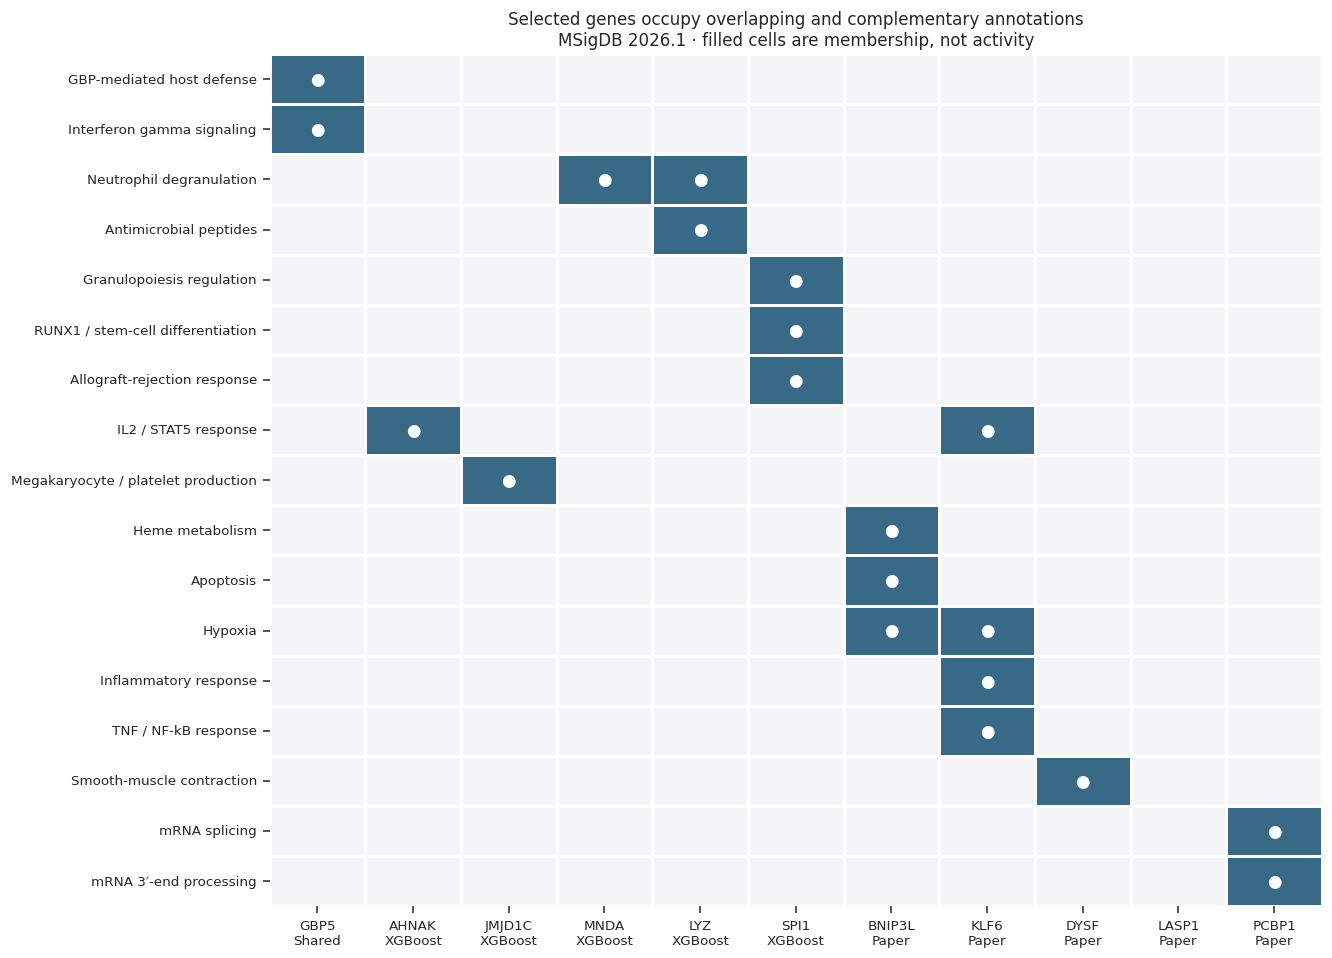

In [11]:
MEMBERSHIP_PATHWAYS = {
    "REACTOME_GBP_MEDIATED_HOST_DEFENSE": "GBP-mediated host defense",
    "REACTOME_INTERFERON_GAMMA_SIGNALING": "Interferon gamma signaling",
    "REACTOME_NEUTROPHIL_DEGRANULATION": "Neutrophil degranulation",
    "REACTOME_ANTIMICROBIAL_PEPTIDES": "Antimicrobial peptides",
    "REACTOME_TRANSCRIPTIONAL_REGULATION_OF_GRANULOPOIESIS": "Granulopoiesis regulation",
    "REACTOME_RUNX1_REGULATES_TRANSCRIPTION_OF_GENES_INVOLVED_IN_DIFFERENTIATION_OF_HSCS": "RUNX1 / stem-cell differentiation",
    "HALLMARK_ALLOGRAFT_REJECTION": "Allograft-rejection response",
    "HALLMARK_IL2_STAT5_SIGNALING": "IL2 / STAT5 response",
    "REACTOME_FACTORS_INVOLVED_IN_MEGAKARYOCYTE_DEVELOPMENT_AND_PLATELET_PRODUCTION": "Megakaryocyte / platelet production",
    "HALLMARK_HEME_METABOLISM": "Heme metabolism",
    "HALLMARK_APOPTOSIS": "Apoptosis",
    "HALLMARK_HYPOXIA": "Hypoxia",
    "HALLMARK_INFLAMMATORY_RESPONSE": "Inflammatory response",
    "HALLMARK_TNFA_SIGNALING_VIA_NFKB": "TNF / NF-kB response",
    "REACTOME_SMOOTH_MUSCLE_CONTRACTION": "Smooth-muscle contraction",
    "REACTOME_MRNA_SPLICING": "mRNA splicing",
    "REACTOME_MRNA_3_END_PROCESSING": "mRNA 3′-end processing",
}
membership_matrix = pd.DataFrame(
    {gene: [int(gene in all_gene_sets[term]) for term in MEMBERSHIP_PATHWAYS] for gene in PANEL_GENES},
    index=list(MEMBERSHIP_PATHWAYS),
)
figure, axis = plt.subplots(figsize=(12, 8.6), layout="constrained")
sns.heatmap(membership_matrix, ax=axis, cmap=["#F3F5F6", "#386A87"], vmin=0, vmax=1,
            cbar=False, linewidths=0.7, annot=membership_matrix.map(lambda value: "●" if value else ""),
            fmt="", annot_kws={"color": "white", "fontsize": 11},
            yticklabels=list(MEMBERSHIP_PATHWAYS.values()),
            xticklabels=[f"{gene}\n{panel_labels[gene]}" for gene in PANEL_GENES])
axis.set(title="Selected genes occupy overlapping and complementary annotations\nMSigDB 2026.1 · filled cells are membership, not activity", xlabel="", ylabel="")
axis.tick_params(axis="both", rotation=0)
save_figure(figure, OUTPUT, "pathway_gene_membership")
plt.show()

### What the membership map tells us

The XGBoost genes span **host defense/interferon (GBP5), granule-associated myeloid biology (MNDA/LYZ), hematopoietic regulation (SPI1/JMJD1C), and signaling scaffolding (AHNAK)**. That is a collection of complementary annotations, rather than six members of one pathway. The paper panel also has immune biology through GBP5, KLF6 and DYSF, alongside erythroid/mitochondrial, cytoskeletal and RNA-related functions. Database coverage is incomplete: the blank LASP1 column does not invalidate its known cytoskeletal function.

## 8. Do the individual genes have consistent TB associations?

Reuse the existing gene-level OLS coefficients and HC3 standard errors rather than fitting another set of genome-wide models. Divide each coefficient and standard error by the gene’s **training SD**. Reconstruct 95% intervals using the original model’s residual degrees of freedom and Student-t cutoff.

The 11 genes × 3 datasets × 2 adjustments form one **BH66** family. This does not correct the earlier supervised selection of these genes. The effects describe expression, not the classifier’s SHAP values, protein activity, or causal effects. Test and validation are exploratory consistency checks in previously inspected data.

**Figure legend — Individual gene expression.** Points show the estimated TB-positive minus TB-negative difference; bars show 95% confidence intervals (CI), using HC3 robust standard errors and Student-t cutoffs. SD means the training standard deviation of the **individual gene's expression**. Positive values indicate higher expression in TB. Row labels identify XGBoost genes, paper-panel genes and their shared gene. Asterisks indicate false discovery rate (FDR) below 0.05 after Benjamini–Hochberg correction across 66 comparisons.

**Adjustment key:** **Study** accounts for which study recruited each participant; **Study + RNA mix** additionally accounts for estimated plasma RNA shares from myeloid cells (including monocytes, macrophages and neutrophils), lymphoid cells (including T, B and natural killer cells), erythroid cells/platelets, and other reference cell types. These are estimated RNA shares, not cell counts. Validation contains one study, so no study indicator is fitted there.

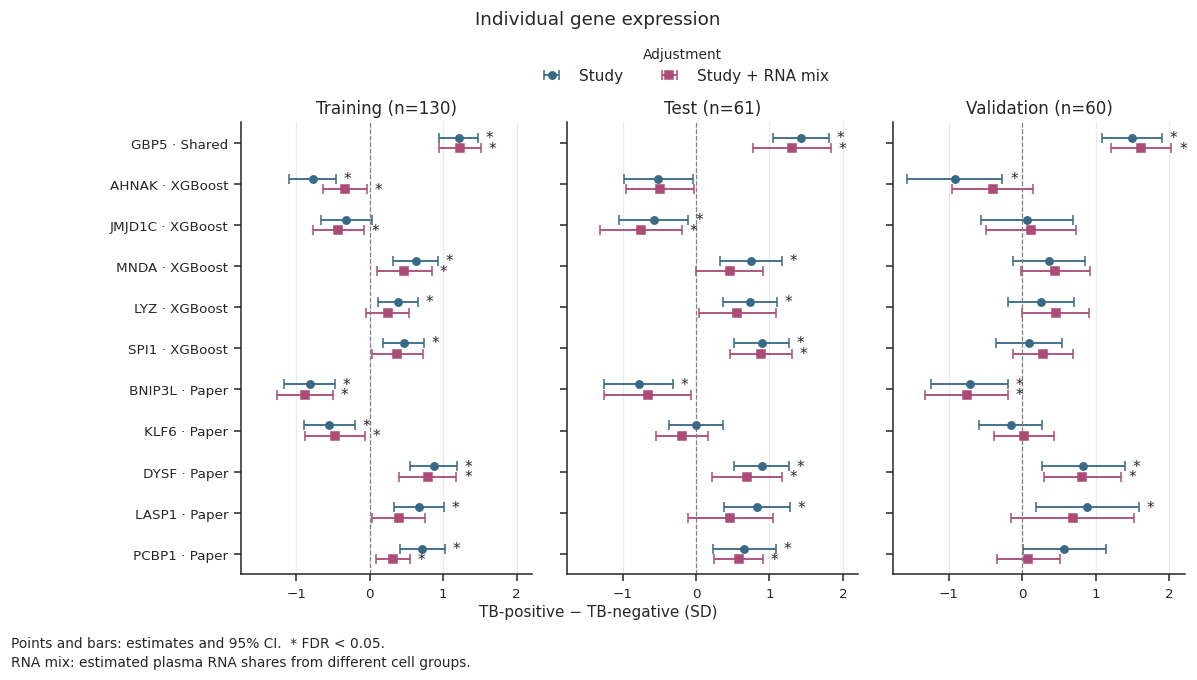

In [12]:
def plot_split_associations(results, row_column, row_order, row_labels, title, xlabel, filename, comparisons):
    """Compare the same two adjustment models on a shared effect scale."""
    figure, axes = plt.subplots(1, 3, figsize=(11, 2.1 + 0.36 * len(row_order)), sharex=True, sharey=True)
    for axis, split in zip(axes, SPLITS):
        for offset, adjustment in zip([-0.13, 0.13], ADJUSTMENTS):
            table = results.loc[results.split.eq(split) & results.adjustment.eq(adjustment)].set_index(row_column).loc[row_order]
            positions = np.arange(len(row_order)) + offset
            axis.errorbar(table.estimate, positions,
                          xerr=[table.estimate - table.ci_lower, table.ci_upper - table.estimate],
                          fmt=ADJUSTMENT_MARKERS[adjustment], color=colors[adjustment], capsize=3, label=ADJUSTMENT_LABELS[adjustment])
            for position, (_, result) in zip(positions, table.iterrows()):
                if result.bh_fdr < 0.05:
                    axis.annotate("*", (result.ci_upper, position), xytext=(5, -3), textcoords="offset points")
        axis.axvline(0, color="0.5", linestyle="--", linewidth=0.8)
        axis.set(title=f"{SPLITS[split]} (n={metadata.split.eq(split).sum()})", yticks=np.arange(len(row_order)),
                 yticklabels=[row_labels[row] for row in row_order], ylim=(len(row_order) - 0.5, -0.5))
        axis.grid(axis="x", color="0.92")
    finish_association_figure(figure, axes, title, xlabel)
    save_figure(figure, OUTPUT, filename)
    plt.show()

selected_effects = gene_results.loc[gene_results.gene.isin(PANEL_GENES)].copy()
training_sd = train_expression[PANEL_GENES].std(ddof=1)
selected_effects["training_sd"] = selected_effects.gene.map(training_sd)
selected_effects["estimate"] = selected_effects.tb_difference / selected_effects.training_sd
selected_effects["standard_error"] = selected_effects.robust_se / selected_effects.training_sd
degrees_freedom = design_audit.assign(residual_df=lambda frame: frame.participants - frame.parameters)
selected_effects = selected_effects.merge(degrees_freedom[["split", "adjustment", "participants", "residual_df"]],
                                        on=["split", "adjustment"], validate="many_to_one")
interval_half_width = t.ppf(0.975, selected_effects.residual_df) * selected_effects.standard_error
selected_effects["ci_lower"] = selected_effects.estimate - interval_half_width
selected_effects["ci_upper"] = selected_effects.estimate + interval_half_width
selected_effects["bh_fdr"] = multipletests(selected_effects.nominal_p, method="fdr_bh")[1]
selected_effects["panel"] = selected_effects.gene.map(panel_labels)
assert len(selected_effects) == 66
selected_effects.to_csv(OUTPUT / "pathway_selected_gene_tb_associations.csv", index=False)
plot_split_associations(selected_effects, "gene", PANEL_GENES,
    {gene: f"{gene} · {panel_labels[gene]}" for gene in PANEL_GENES},
    "Individual gene expression",
    "TB-positive − TB-negative (SD)", "pathway_selected_gene_tb_associations", comparisons=66)
display(selected_effects.loc[selected_effects.adjustment.eq(ADJUSTMENTS[1])]
    .pivot(index="gene", columns="split", values=["estimate", "bh_fdr"])
    .reindex(index=PANEL_GENES, columns=pd.MultiIndex.from_product([["estimate", "bh_fdr"], SPLITS]))
    .style.format(precision=3))

### Observed gene-level differences

After accounting for study differences and estimated RNA contributions, GBP5 is higher in TB by **1.23 / 1.31 / 1.62 training SD** in training/test/validation. It is the only XGBoost gene meeting BH66 < 0.05 in all three datasets. MNDA, LYZ and SPI1 have positive estimates throughout, but their individual adjusted differences remain uncertain in at least one dataset. AHNAK has negative estimates throughout; JMJD1C changes from negative in training/test to a small, uncertain positive estimate in validation.

The paper panel should not be dismissed biologically: **DYSF** has positive adjusted differences of **0.79 / 0.69 / 0.82 SD**, passing BH66 in all three datasets. BNIP3L is consistently negative; its test q value is 0.05005, very close to the conventional cutoff. Such a borderline value is not a biological dividing line. Individual expression differences do not measure predictive importance in a multivariable classifier.

## 9. Which broader programs does each gene track?

Alongside the original five themes, add **IL2–STAT5** for the AHNAK-related hypothesis, **megakaryocyte/platelet production** for the JMJD1C alternative, and a **signed SPI1 target-expression score**. These literature-motivated additions were chosen before computing these new associations, but the overall study remains exploratory.

All eight new scores exclude **all 11 panel genes**. This removes direct self-inclusion; it does not remove correlated genes, shared RNA sources, or normalization effects. These scores have new names and outputs so the original five scores and BH30 results remain separate.

For curated sets, average the existing gene training z scores and divide by the average's training standard deviation. For SPI1 targets, average `sign × gene z score` and apply the same scaling. A positive sign denotes annotated activation and a negative sign annotated repression; neither is an effect size fitted from these data.

### Why the SPI1 score is an expression proxy

[DoRothEA](https://pubmed.ncbi.nlm.nih.gov/31340985/) and [CollecTRI](https://pmc.ncbi.nlm.nih.gov/articles/PMC10639077/) support testing signed target programs, with context-dependent limitations. We use a small pinned DoRothEA human v1.7.4 extract (commit `1461fb75e23e110c2281860526d4333920925282`), retaining confidence A/B. Here all 102 SPI1 targets are labeled A; 82 are expressed, and removing MNDA leaves **81 targets (76 positive, 5 negative)**. This transparent signed average is **not VIPER**, a measurement of PU.1 binding, or validated biochemical activity in plasma.

There is a useful warning in the primary literature: although the database lists MNDA as a SPI1 target, [human promoter experiments](https://pubmed.ncbi.nlm.nih.gov/9136080/) found no significant effect from mutating the tested PU.1 site, while a **Sp1** site was functional. **SP1 and SPI1 are different genes.** We exclude MNDA from the score and do not draw a proven SPI1→MNDA regulatory arrow. The experiment does not rule out every possible context or distal regulatory element.

In [13]:
GENE_PROGRAMS = {
    **FOCUS,
    "HALLMARK_IL2_STAT5_SIGNALING": "IL2 / STAT5",
    "REACTOME_FACTORS_INVOLVED_IN_MEGAKARYOCYTE_DEVELOPMENT_AND_PLATELET_PRODUCTION": "Megakaryocyte / platelet",
    "SPI1_TARGETS": "SPI1 signed targets",
}
spi1_file = RESOURCES / "spi1_dorothea_targets.tsv"
spi1_manifest = json.loads((RESOURCES / "spi1_dorothea_sources.json").read_text())
assert hashlib.sha256(spi1_file.read_bytes()).hexdigest() == spi1_manifest["subset_sha256"]
spi1_targets = pd.read_csv(spi1_file, sep="\t")
assert spi1_targets.target.is_unique and spi1_targets.tf.eq("SPI1").all()
assert spi1_targets.confidence.isin(["A", "B"]).all() and spi1_targets.mor.isin([-1, 1]).all()
spi1_targets["expressed"] = spi1_targets.target.isin(expression.columns)
spi1_targets["excluded_panel_gene"] = spi1_targets.target.isin(PANEL_GENES)
spi1_targets["used"] = spi1_targets.expressed & ~spi1_targets.excluded_panel_gene
spi1_targets.to_csv(OUTPUT / "pathway_spi1_target_coverage.csv", index=False)

program_weights = {}
for term in GENE_PROGRAMS:
    if term == "SPI1_TARGETS":
        weights = spi1_targets.loc[spi1_targets.used].set_index("target").mor.astype(float)
    else:
        members = sorted((set(all_gene_sets[term]) & set(expression.columns)) - set(PANEL_GENES))
        weights = pd.Series(1.0, index=members)
    assert len(weights) >= 15 and not set(weights.index) & set(PANEL_GENES)
    program_weights[term] = weights

gene_program_scores = pd.DataFrame(index=metadata.index)
for term, weights in program_weights.items():
    raw_score = standardized.loc[:, weights.index].mul(weights, axis=1).mean(axis=1)
    gene_program_scores[term] = raw_score / raw_score.loc[metadata.split.eq("train")].std(ddof=1)
assert np.isfinite(gene_program_scores).all().all()
np.testing.assert_allclose(gene_program_scores.loc[metadata.split.eq("train")].std(ddof=1), 1)
gene_program_scores.to_csv(OUTPUT / "pathway_panel_excluded_program_scores.csv")
(OUTPUT / "pathway_panel_excluded_program_weights.json").write_text(json.dumps(
    {term: weights.to_dict() for term, weights in program_weights.items()}, indent=2))
program_coverage = pd.DataFrame([
    {"program": term, "genes_used": len(weights), "positive_weights": int(weights.gt(0).sum()),
     "negative_weights": int(weights.lt(0).sum())} for term, weights in program_weights.items()
])
program_coverage.to_csv(OUTPUT / "pathway_gene_program_coverage.csv", index=False)
display(program_coverage.replace({"program": GENE_PROGRAMS}).style.hide(axis="index"))

program,genes_used,positive_weights,negative_weights
Interferon alpha,91,91,0
Interferon gamma,185,185,0
TNF / NF-kB,156,156,0
Inflammatory response,131,131,0
Neutrophil degranulation,402,402,0
IL2 / STAT5,144,144,0
Megakaryocyte / platelet,123,123,0
SPI1 signed targets,81,76,5


### First check the programs’ TB-associated expression

Use the existing two adjustment designs and HC3/t intervals. The eight programs × three datasets × two adjustments receive one **BH48** correction. These all-panel-excluded estimates complement the original analysis; they do not replace its BH30 values. IL2–STAT5 is a response signature, and the megakaryocyte program is not a measured platelet count.

**Figure legend — Broader expression patterns.** All 11 genes from the union of both panels are excluded from these program averages. Points show the estimated TB-positive minus TB-negative difference; bars show 95% confidence intervals (CI), using HC3 robust standard errors and Student-t cutoffs. SD means the training standard deviation of the **program score**. Positive values indicate higher expression in TB. Asterisks indicate false discovery rate (FDR) below 0.05 after Benjamini–Hochberg correction across 48 comparisons.

**Adjustment key:** **Study** accounts for which study recruited each participant; **Study + RNA mix** additionally accounts for estimated plasma RNA shares from myeloid cells (including monocytes, macrophages and neutrophils), lymphoid cells (including T, B and natural killer cells), erythroid cells/platelets, and other reference cell types. These are estimated RNA shares, not cell counts. Validation contains one study, so no study indicator is fitted there.

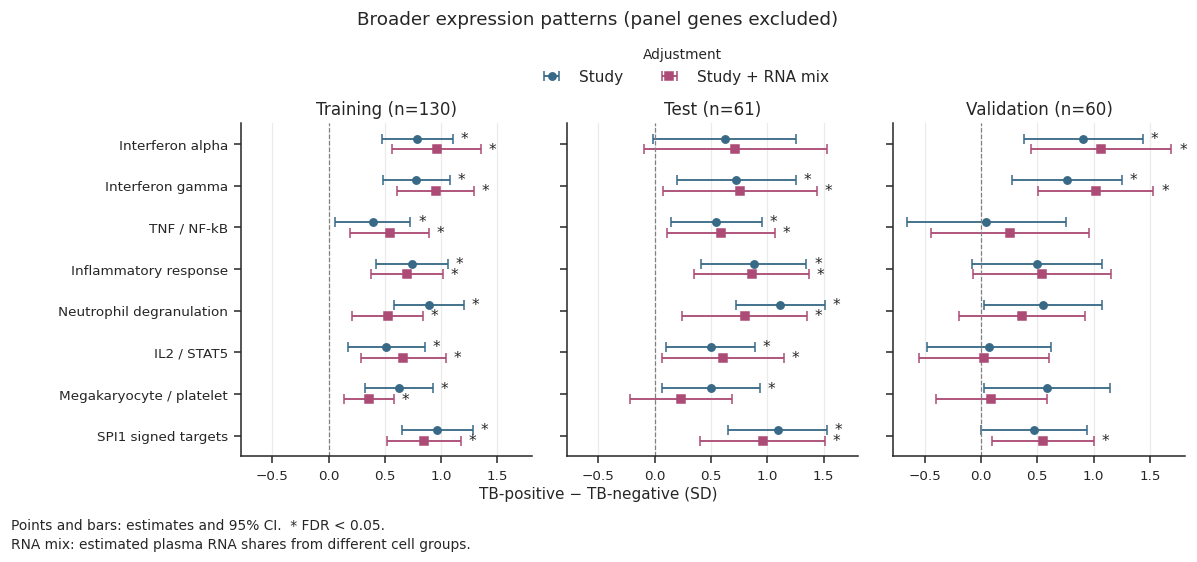

In [14]:
def association_result(outcome, design, term):
    """Estimate one coefficient and its participant-level HC3/t uncertainty."""
    assert outcome.index.equals(design.index)
    assert np.linalg.matrix_rank(design) == design.shape[1]
    fit = sm.OLS(outcome, design, missing="raise").fit(cov_type="HC3", use_t=True)
    lower, upper = fit.conf_int().loc[term]
    return {"estimate": fit.params[term], "standard_error": fit.bse[term],
            "ci_lower": lower, "ci_upper": upper, "nominal_p": fit.pvalues[term],
            "n": int(fit.nobs), "residual_df": int(fit.df_resid)}

program_effect_rows = []
for split in SPLITS:
    frame = metadata.loc[metadata.split.eq(split)]
    for adjustment in ADJUSTMENTS:
        design = make_design(frame, adjustment)
        for term in GENE_PROGRAMS:
            result = association_result(gene_program_scores.loc[frame.index, term], design, "tb_positive")
            program_effect_rows.append({**result, "program": term, "split": split, "adjustment": adjustment})
program_effects = pd.DataFrame(program_effect_rows)
program_effects["bh_fdr"] = multipletests(program_effects.nominal_p, method="fdr_bh")[1]
assert len(program_effects) == 48
program_effects.to_csv(OUTPUT / "pathway_gene_program_tb_associations.csv", index=False)
plot_split_associations(program_effects, "program", list(GENE_PROGRAMS), GENE_PROGRAMS,
    "Broader expression patterns (panel genes excluded)",
    "TB-positive − TB-negative (SD)", "pathway_gene_program_tb_associations", comparisons=48)

### Observed broader-program differences

The **interferon-gamma** and **SPI1 signed-target** scores have positive TB differences after accounting for study differences and estimated RNA contributions in all three datasets and pass BH48 throughout. For SPI1 targets the differences are **0.85 / 0.96 / 0.55 program SD**; validation's 95% interval is **0.10 to 1.00 SD**. Validation's target-score interval when accounting for study differences alone includes zero, so its statistical support depends on the adjustment specification. This supports an associated target-expression pattern, not direct PU.1 activation.

IL2/STAT5 differs by **0.66 / 0.61 / 0.03 SD** after adjustment, and the megakaryocyte/platelet score by **0.36 / 0.23 / 0.09 SD**. Neither provides a consistent TB-associated difference across all three datasets. The neutrophil, inflammatory and TNF summaries are also uncertain in validation. A gene can track a program between people even when that program does not clearly distinguish TB status in every dataset; the next analysis addresses that different question.

### Then link each XGBoost gene to the broader programs

Relate each program average to each gene while accounting for TB status and study differences; repeat while also accounting for the estimated RNA contributions from the four cell groups. The coefficient is the **program training-SD difference per gene training SD**, conditional on the other terms. Controlling TB avoids merely rediscovering case/control separation. The outcome/predictor choice is a modeling convention, not a causal direction.

Apply one **BH288** correction to 6 genes × 8 programs × 3 datasets × 2 adjustments. The figure displays every comparison, not only significant cells. Slopes are not correlations and can exceed one. Exact HC3/t intervals are exported beside the heatmap. A change with adjustment is a sensitivity result, not a percent-mediated estimate.

**Figure legend — Gene–program associations.** Each value is the change in program expression, measured in its training standard deviation (SD), per one training SD of gene expression. All models also account for TB status, and all 11 panel genes are excluded from program averages. These values are regression slopes, not correlations. Asterisks indicate false discovery rate (FDR) below 0.05 after Benjamini–Hochberg correction across 288 comparisons. The accompanying numerical table contains 95% confidence intervals using HC3 robust standard errors and Student-t cutoffs.

**Adjustment key:** **Study** accounts for which study recruited each participant; **Study + RNA mix** additionally accounts for estimated plasma RNA shares from myeloid cells (including monocytes, macrophages and neutrophils), lymphoid cells (including T, B and natural killer cells), erythroid cells/platelets, and other reference cell types. These are estimated RNA shares, not cell counts. Validation contains one study, so no study indicator is fitted there.

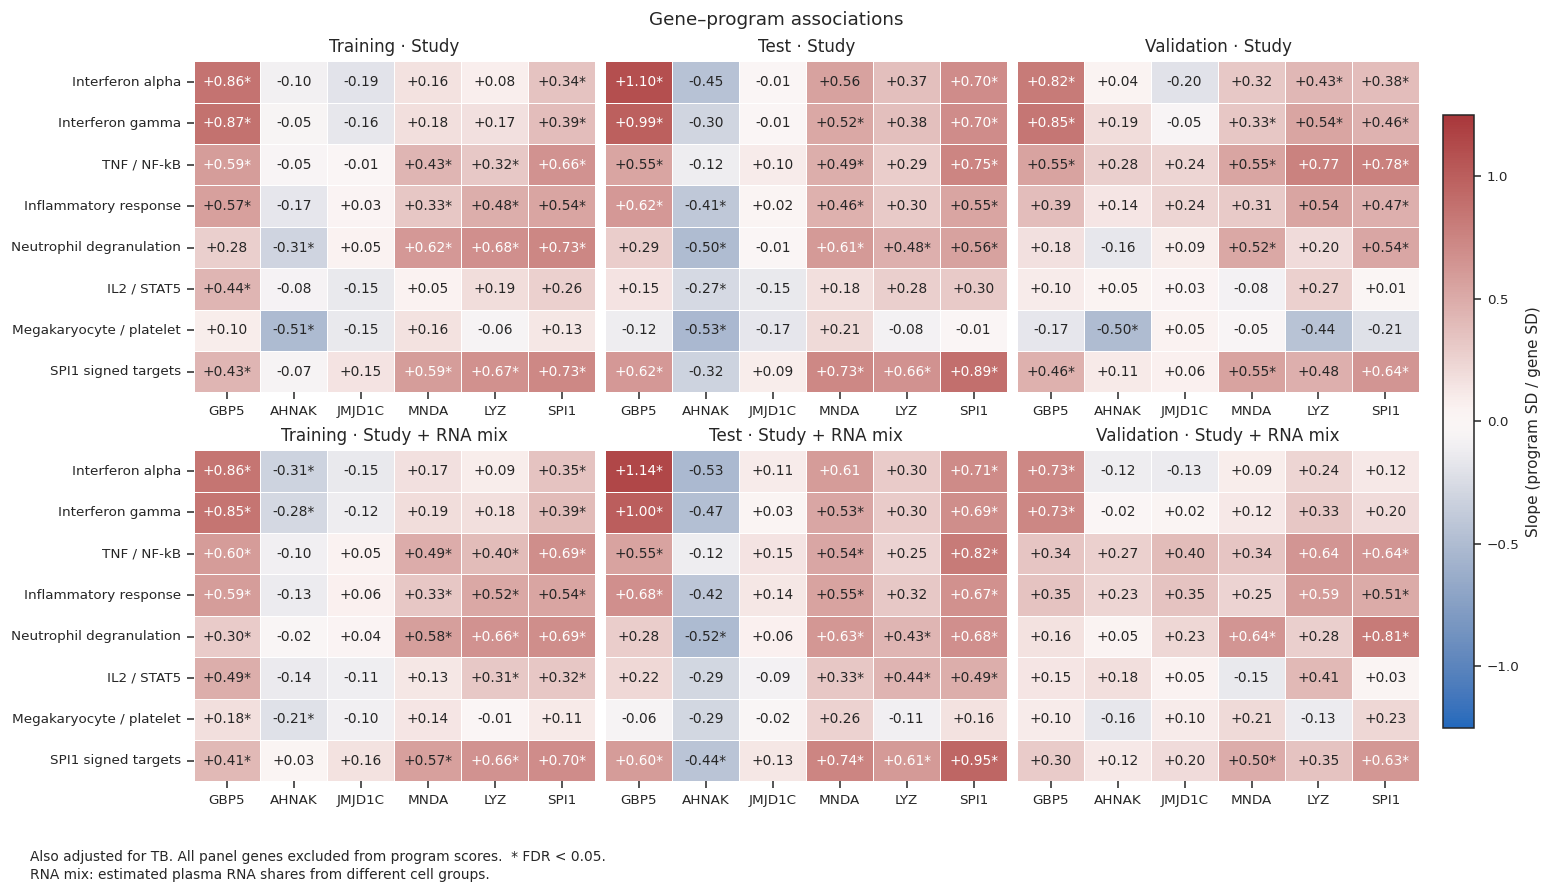

In [15]:
coupling_rows = []
for split in SPLITS:
    frame = metadata.loc[metadata.split.eq(split)]
    for adjustment in ADJUSTMENTS:
        base_design = make_design(frame, adjustment)
        for gene in SELECTED:
            design = base_design.assign(gene_expression=standardized.loc[frame.index, gene])
            for term in GENE_PROGRAMS:
                result = association_result(gene_program_scores.loc[frame.index, term], design, "gene_expression")
                coupling_rows.append({**result, "gene": gene, "program": term, "split": split, "adjustment": adjustment})
gene_program_associations = pd.DataFrame(coupling_rows)
gene_program_associations["bh_fdr"] = multipletests(gene_program_associations.nominal_p, method="fdr_bh")[1]
assert len(gene_program_associations) == 288
gene_program_associations.to_csv(OUTPUT / "pathway_gene_program_associations.csv", index=False)

figure, axes = plt.subplots(2, 3, figsize=(14, 8), layout="constrained")
limit = np.ceil(gene_program_associations.estimate.abs().max() * 4) / 4
for row, adjustment in enumerate(ADJUSTMENTS):
    for column, split in enumerate(SPLITS):
        table = gene_program_associations.loc[gene_program_associations.split.eq(split) & gene_program_associations.adjustment.eq(adjustment)]
        values = table.pivot(index="program", columns="gene", values="estimate").reindex(index=GENE_PROGRAMS, columns=SELECTED)
        fdr = table.pivot(index="program", columns="gene", values="bh_fdr").reindex_like(values)
        labels = values.map(lambda value: f"{value:+.2f}") + fdr.map(lambda value: "*" if value < 0.05 else "")
        sns.heatmap(values, ax=axes[row, column], annot=labels, fmt="", cmap="vlag", center=0,
                    vmin=-limit, vmax=limit, cbar=False, linewidths=0.5,
                    xticklabels=SELECTED, yticklabels=list(GENE_PROGRAMS.values()) if column == 0 else False, annot_kws={"fontsize": 9})
        axes[row, column].set(title=f"{SPLITS[split]} · {ADJUSTMENT_TITLES[adjustment]}", xlabel="", ylabel="")
        axes[row, column].tick_params(axis="both", rotation=0)
figure.colorbar(axes[0, 0].collections[0], ax=axes, fraction=0.025, pad=0.02,
               label="Slope (program SD / gene SD)")
figure.suptitle("Gene–program associations", fontsize=12)
figure.set_layout_engine("constrained", rect=(0, 0.085, 1, 0.915))
add_figure_caption(figure, "Also adjusted for TB. All panel genes excluded from program scores.  * FDR < 0.05.")
save_figure(figure, OUTPUT, "pathway_gene_program_associations")
plt.show()

### Which gene-to-program links are consistent?

All numbers below come from the models accounting for TB status, study differences and estimated RNA contributions; sequences are training/test/validation.

- **GBP5:** the interferon-gamma slopes are **0.85 / 1.00 / 0.73 program SD per gene SD**, with BH288 < 0.05 throughout. The corresponding interferon-alpha links are also supported in all three datasets. GBP5 is therefore a useful reporter of the wider interferon expression pattern, even after excluding every panel gene from the score.
- **MNDA and SPI1:** both consistently track neutrophil-degranulation and SPI1-target scores. MNDA–neutrophil slopes are **0.58 / 0.63 / 0.64**; SPI1–target slopes are **0.70 / 0.95 / 0.63**. SPI1 also consistently tracks TNF and inflammatory scores. These overlapping programs are related evidence, not independent mechanistic confirmations.
- **LYZ:** its neutrophil association is supported in training/test, but the validation slope is **0.28**, with a wide **−0.61 to 1.17** interval. Its broad myeloid annotation remains plausible, while its observed relationship is less consistent than MNDA's or SPI1's.
- **AHNAK and JMJD1C:** the proposed AHNAK–IL2/STAT5 and JMJD1C–megakaryocyte links do not meet the consistency criterion. Their slopes change sign and their adjusted intervals include zero. These literature-based hypotheses are not substantiated by this analysis; a linear negative result does not rule out other contexts or nonlinear associations.

Each gene is tested separately as a predictor of a program. These coefficients are not unique contributions after controlling for the other five selected genes, and shared expression sources can still contribute after accounting for estimated RNA contributions from broad cell groups.

## 10. Do the six genes share the same expression pattern?

The combination can contain both shared and complementary signals. For each split, account for TB status and study differences in all six scaled gene-expression values; repeat while also accounting for estimated RNA contributions. Correlate the residual gene-expression vectors using Pearson r. This describes covariation remaining after the modeled terms are removed. It is a linear partial correlation, not the rank correlation used in the earlier myeloid analysis.

These correlations are descriptive, with no significance stars or causal edges. Held-out samples are small, so correlations can be unstable. Gene-expression correlation and pairwise SHAP answer different questions: one concerns covariation between participants, while the other concerns nonadditivity in the fitted classifier.

**Figure legend — Gene coexpression.** Numbers show Pearson correlations between gene-expression differences remaining after adjustment. All models also account for TB status. Positive values mean the two genes tend to vary together; negative values mean opposite directions. These descriptive correlations do not have confidence intervals or significance tests and do not imply regulatory direction.

**Adjustment key:** **Study** accounts for which study recruited each participant; **Study + RNA mix** additionally accounts for estimated plasma RNA shares from myeloid cells (including monocytes, macrophages and neutrophils), lymphoid cells (including T, B and natural killer cells), erythroid cells/platelets, and other reference cell types. These are estimated RNA shares, not cell counts. Validation contains one study, so no study indicator is fitted there.

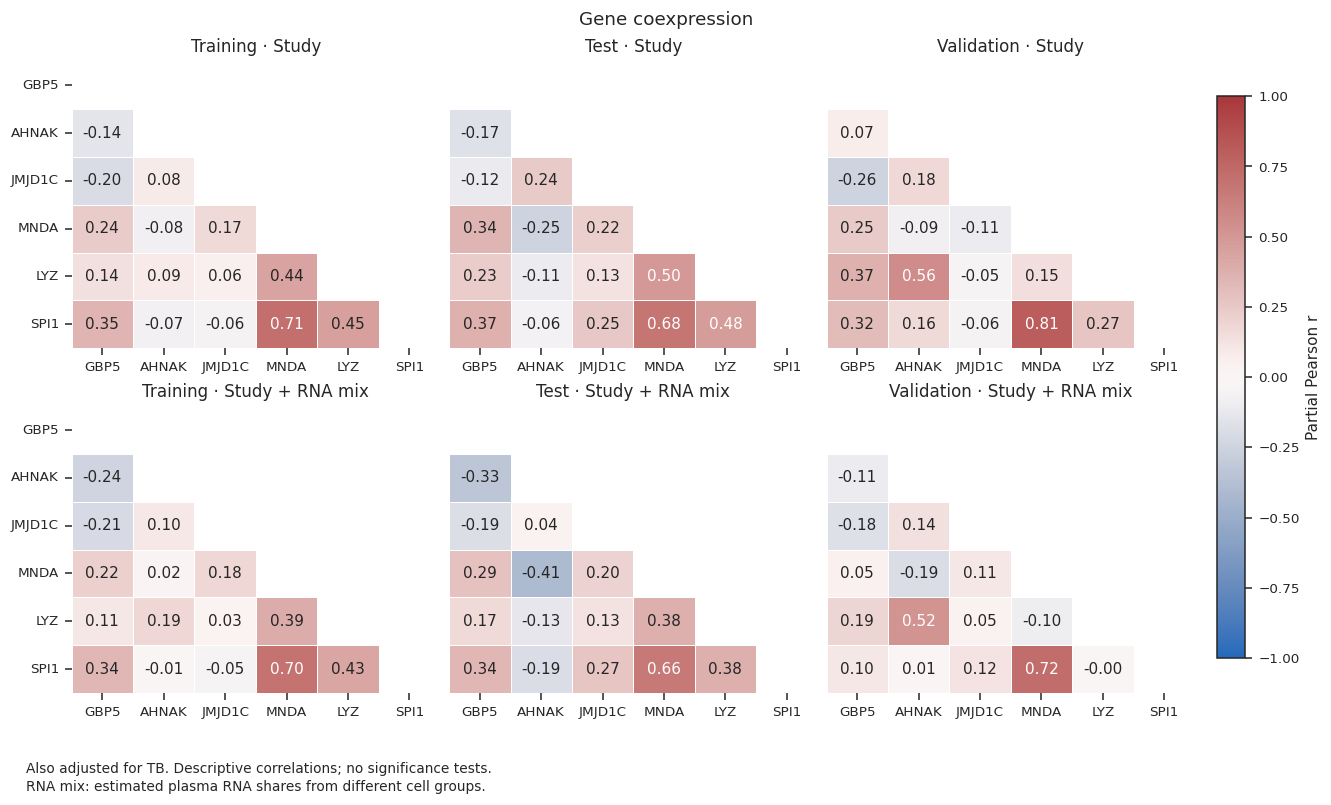

In [16]:
pair_rows = []
figure, axes = plt.subplots(2, 3, figsize=(12, 7.2), layout="constrained")
for row, adjustment in enumerate(ADJUSTMENTS):
    for column, split in enumerate(SPLITS):
        frame = metadata.loc[metadata.split.eq(split)]
        design = make_design(frame, adjustment)
        values = standardized.loc[frame.index, SELECTED]
        residual_values = values.to_numpy() - design.to_numpy() @ np.linalg.lstsq(design, values, rcond=None)[0]
        residuals = pd.DataFrame(residual_values, index=frame.index, columns=SELECTED)
        correlations = residuals.corr()
        assert np.isfinite(correlations).all().all()
        for first in range(len(SELECTED)):
            for second in range(first):
                pair_rows.append({"gene_1": SELECTED[second], "gene_2": SELECTED[first],
                    "split": split, "adjustment": adjustment, "n": len(frame),
                    "partial_pearson_r": correlations.iloc[first, second]})
        sns.heatmap(correlations, mask=np.triu(np.ones_like(correlations, dtype=bool)),
                    ax=axes[row, column], annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
                    cbar=False, linewidths=0.5, xticklabels=SELECTED, yticklabels=SELECTED if column == 0 else False)
        axes[row, column].set(title=f"{SPLITS[split]} · {ADJUSTMENT_TITLES[adjustment]}", xlabel="", ylabel="")
        axes[row, column].tick_params(axis="both", rotation=0)
figure.colorbar(axes[0, 0].collections[0], ax=axes, fraction=0.025, pad=0.02, label="Partial Pearson r")
figure.suptitle("Gene coexpression", fontsize=12)
figure.set_layout_engine("constrained", rect=(0, 0.095, 1, 0.905))
add_figure_caption(figure, "Also adjusted for TB. Descriptive correlations; no significance tests.")
save_figure(figure, OUTPUT, "pathway_selected_gene_coexpression")
plt.show()
gene_pairs = pd.DataFrame(pair_rows)
assert len(gene_pairs) == 90
gene_pairs.to_csv(OUTPUT / "pathway_selected_gene_coexpression.csv", index=False)

### The myeloid genes are not one uniform block

**MNDA–SPI1** remains strongly correlated after adjustment: **r = 0.70 / 0.66 / 0.72**. In contrast, **MNDA–LYZ** is **0.39 / 0.38 / −0.10**, and **LYZ–SPI1** is **0.43 / 0.38 / approximately 0.00**. This supports a persistent MNDA/SPI1 expression relationship more clearly than a stable three-gene block. These descriptive correlations have no intervals here, so differences between datasets are not formal tests of changing correlation.

### Keep evidence about gene pairs in separate columns

The table compares all 15 pairs: the exact shared curated annotations, residual expression correlation in each split, and the previously saved mean absolute pairwise SHAP. Shared Reactome parent/child terms are listed rather than counted as independent mechanisms. SHAP remains in **log-odds units** and was calculated with the original model’s split-specific VST; the correlations here use **training-reference VST**. Agreement is descriptive, and disagreement is not a calculation error.

In [17]:
shared_annotations = []
for first in range(len(SELECTED)):
    for second in range(first):
        gene_1, gene_2 = SELECTED[second], SELECTED[first]
        terms = [term for term, members in all_gene_sets.items() if gene_1 in members and gene_2 in members]
        shared_annotations.append({"gene_1": gene_1, "gene_2": gene_2, "shared_annotations": "; ".join(terms) or "None in pinned collections"})
pair_evidence = pd.DataFrame(shared_annotations)
residual_table = gene_pairs.loc[gene_pairs.adjustment.eq(ADJUSTMENTS[1])].pivot(
    index=["gene_1", "gene_2"], columns="split", values="partial_pearson_r").add_prefix("residual_r_")
pair_evidence = pair_evidence.merge(residual_table, on=["gene_1", "gene_2"], validate="one_to_one")
shap_pair_file = OUTPUT / "xgboost_cv_shap_interactions.csv"
shap_pair_results = pd.read_csv(shap_pair_file)
for table in [pair_evidence, shap_pair_results]:
    table["pair_key"] = [tuple(sorted(pair)) for pair in zip(table.gene_1, table.gene_2)]
assert not shap_pair_results.duplicated(["pair_key", "split"]).any()
shap_pairs_wide = shap_pair_results.pivot(index="pair_key", columns="split", values="mean_abs_pair_log_odds").add_prefix("shap_pair_log_odds_")
pair_evidence = pair_evidence.merge(shap_pairs_wide, on="pair_key", validate="one_to_one").drop(columns="pair_key")
assert len(pair_evidence) == 15 and not pair_evidence.isna().any().any()
pair_evidence.to_csv(OUTPUT / "pathway_gene_pair_evidence.csv", index=False)
pair_display = pd.DataFrame({
    "Gene pair": pair_evidence.gene_1 + "–" + pair_evidence.gene_2,
    "Shared annotations": pair_evidence.shared_annotations.str.replace("REACTOME_", "").str.replace("HALLMARK_", "").str.replace("_", " ").str.title(),
    "Residual r: train / test / val": pair_evidence[[f"residual_r_{split}" for split in SPLITS]].apply(lambda row: " / ".join(f"{value:+.2f}" for value in row), axis=1),
    "Mean absolute pair SHAP: train / test / val": pair_evidence[[f"shap_pair_log_odds_{split}" for split in SPLITS]].apply(lambda row: " / ".join(f"{value:.3f}" for value in row), axis=1),
})
display(pair_display.style.hide(axis="index"))

Gene pair,Shared annotations,Residual r: train / test / val,Mean absolute pair SHAP: train / test / val
GBP5–AHNAK,None In Pinned Collections,-0.24 / -0.33 / -0.11,0.137 / 0.152 / 0.266
GBP5–JMJD1C,None In Pinned Collections,-0.21 / -0.19 / -0.18,0.122 / 0.098 / 0.220
AHNAK–JMJD1C,None In Pinned Collections,+0.10 / +0.04 / +0.14,0.000 / 0.000 / 0.000
GBP5–MNDA,None In Pinned Collections,+0.22 / +0.29 / +0.05,0.077 / 0.072 / 0.094
AHNAK–MNDA,None In Pinned Collections,+0.02 / -0.41 / -0.19,0.096 / 0.084 / 0.209
JMJD1C–MNDA,None In Pinned Collections,+0.18 / +0.20 / +0.11,0.016 / 0.012 / 0.017
GBP5–LYZ,None In Pinned Collections,+0.11 / +0.17 / +0.19,0.082 / 0.074 / 0.062
AHNAK–LYZ,None In Pinned Collections,+0.19 / -0.13 / +0.52,0.000 / 0.000 / 0.000
JMJD1C–LYZ,None In Pinned Collections,+0.03 / +0.13 / +0.05,0.054 / 0.058 / 0.091
MNDA–LYZ,Innate Immune System; Neutrophil Degranulation,+0.39 / +0.38 / -0.10,0.088 / 0.081 / 0.085


### Coexpression and predictive interactions answer different questions

MNDA–SPI1 has strong residual coexpression but **zero saved pairwise SHAP interaction** in all three datasets, and no shared annotation in the scanned collections. No pairwise nonadditive SHAP contribution was attributed to this pair for the evaluated participants; it does not mean the genes lack biological connections.

Conversely, GBP5–AHNAK has the largest mean absolute pair SHAP in each split (**0.137 / 0.152 / 0.266 log-odds**), despite no shared term and modest negative residual correlations. The model can combine different biological signals to predict TB. Absolute SHAP interaction magnitude does not specify synergy versus antagonism, and neither SHAP nor coexpression establishes physical interaction or epistasis.

## 11. Build the biological story from agreement and disagreement

Read the evidence in layers: literature identifies plausible functions; membership specifies what is actually annotated; the gene effects establish observed directions; gene–program slopes ask which wider patterns track the genes after accounting for TB status and study differences; estimated RNA contributions and residual correlations help examine source-related explanations. The SPI1 target score provides a broader regulatory-expression hypothesis without equating SPI1 RNA with PU.1 activity.

The final numerical summary below uses the models accounting for study differences and estimated RNA contributions and reports every gene, including uncertain or inconsistent findings. “Same sign” is only directional consistency. It does not mean equivalence of effects or confirmation of a mechanism. Multiple-testing corrections do not account for the earlier selection of these genes or research questions.

In [18]:
gene_summary_rows = []
for gene in SELECTED:
    effects = selected_effects.loc[selected_effects.gene.eq(gene) & selected_effects.adjustment.eq(ADJUSTMENTS[1])].set_index("split").loc[list(SPLITS)]
    same_sign = effects.estimate.gt(0).all() or effects.estimate.lt(0).all()
    linked_programs = []
    for term, label in GENE_PROGRAMS.items():
        links = gene_program_associations.loc[gene_program_associations.gene.eq(gene) &
            gene_program_associations.program.eq(term) & gene_program_associations.adjustment.eq(ADJUSTMENTS[1])]
        concordant = links.estimate.gt(0).all() or links.estimate.lt(0).all()
        if concordant and links.bh_fdr.lt(0.05).all():
            linked_programs.append(("+ " if links.estimate.gt(0).all() else "− ") + label)
    gene_summary_rows.append({"gene": gene,
        "TB effect train / test / validation (SD)": " / ".join(f"{value:+.2f}" for value in effects.estimate),
        "TB direction consistent": bool(same_sign),
        "TB BH66 < 0.05 in all splits": bool(effects.bh_fdr.lt(0.05).all()),
        "Program links with same sign and BH288 < 0.05 in all splits": "; ".join(linked_programs) or "None meeting the all-three-split criterion"})
gene_story = pd.DataFrame(gene_summary_rows)
gene_story.to_csv(OUTPUT / "pathway_gene_story_summary.csv", index=False)
display(gene_story.style.hide(axis="index"))

gene_provenance = {
    "input_sha256": {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest() for path in
        [hallmark_file, reactome_file, spi1_file, RESOURCES / "spi1_dorothea_sources.json",
         RESOURCES / "gene_function_evidence.json", shap_pair_file, OUTPUT / "pathway_provenance.json"]},
    "xgboost_genes": SELECTED, "paper_genes": PAPER_GENES, "excluded_from_new_scores": PANEL_GENES,
    "programs": GENE_PROGRAMS, "expression_source": "Training-reference VST; original pathway inputs and hashes are recorded in pathway_provenance.json",
    "gene_bh_tests": len(selected_effects), "program_bh_tests": len(program_effects),
    "gene_program_bh_tests": len(gene_program_associations), "residual_pairs_descriptive": len(gene_pairs),
    "program_standardization": "Gene and composite sample SDs fitted on training only; signed mean for SPI1, equal positive means for curated sets",
    "regression": "Separate splits; TB + cohort with/without broad composition; HC3 covariance and residual-df t intervals",
    "pair_shap_source": "Saved original model explanation; separate split-specific VST, not the new expression matrix",
    "packages": {name: version(name) for name in ["numpy", "pandas", "scipy", "statsmodels", "gseapy"]},
    "resources": "Numerical libraries limited to one thread; GSEA workers limited to two",
    "literature_review_date": "2026-10-21",
}
(OUTPUT / "pathway_gene_interpretation_provenance.json").write_text(json.dumps(gene_provenance, indent=2))
print(f"Gene-focused figures, exact effects, membership and provenance saved to {OUTPUT}")

gene,TB effect train / test / validation (SD),TB direction consistent,TB BH66 < 0.05 in all splits,Program links with same sign and BH288 < 0.05 in all splits
GBP5,+1.23 / +1.31 / +1.62,True,True,+ Interferon alpha; + Interferon gamma
AHNAK,-0.34 / -0.49 / -0.40,True,False,None meeting the all-three-split criterion
JMJD1C,-0.43 / -0.75 / +0.12,False,False,None meeting the all-three-split criterion
MNDA,+0.47 / +0.46 / +0.45,True,False,+ Neutrophil degranulation; + SPI1 signed targets
LYZ,+0.24 / +0.56 / +0.46,True,False,None meeting the all-three-split criterion
SPI1,+0.38 / +0.89 / +0.28,True,False,+ TNF / NF-kB; + Inflammatory response; + Neutrophil degranulation; + SPI1 signed targets


Gene-focused figures, exact effects, membership and provenance saved to /local/workdir/amz63/cfRNA_TB/Figure_Output/Gene_Interactions/focused


### A biological story supported by these results

> The XGBoost panel combines an interferon-associated host-response component, represented most clearly by GBP5, with a broader myeloid-related expression component represented by MNDA and SPI1. These relationships extend beyond the selected genes and remain detectable after adjustment for TB status, study differences and estimated RNA contributions from broad cell groups. LYZ is biologically compatible with the myeloid interpretation but shows weaker cross-dataset consistency. AHNAK and JMJD1C may contribute complementary predictive information; their proposed T-cell-signaling and megakaryocyte links are not consistently supported by the current expression analyses. The panel therefore supports a combined host-response interpretation rather than one demonstrated causal pathway.

The strongest next checks are **source-specific replication** and **regulatory validation**. First, compare these exact program definitions against matched blood counts or an independent cell-reference analysis. Separately, use the existing gene-excluded deconvolution as a robustness check on the same cfRNA samples; it is not independent replication. Test the MNDA/SPI1 relationship within monocyte and neutrophil populations in an independent TB single-cell dataset, with participants—not individual cells—as biological replicates. Second, a direct PU.1 regulatory claim would require relevant-cell binding and perturbation evidence; the plasma associations alone cannot establish it. AHNAK and JMJD1C should remain explicit alternative hypotheses until independent evidence narrows their roles.

These are exploratory analyses of already inspected samples. Persistence after adjustment does not fully separate differences in RNA sources from changes within cells, because the RNA-share estimates come from the same assay and are uncertain. The paper panel remains biologically plausible, and biological narrative strength should be assessed separately from predictive performance.